
# OnTarget — Soccer Goal Probability Prediction Using Deep Learning

**Course:** ARTE4110U — Deep Learning Architectures and Algorithms

**Project:** Final Project — OnTarget

**Group Number:** [Insert Group Number]

**Team Members:**
- Gitae Yang — 100794460
- Arno Nazarian — 100868853
- Nievethan Thanienayagam — 100750591

**Dataset:** StatsBomb Open Data

**Frameworks:** PyTorch and Scikit-learn

**GitHub Repository:** https://github.com/Nievethan/OnTarget

---

## Project Overview

The goal of OnTarget is to predict the probability that a soccer shot will result in a goal using machine learning and deep learning.

The model considers information available when a shot is taken, such as the distance to the goal, shooting angle, body part, shot technique, defensive pressure, and goalkeeper positioning.

This project compares two models:

1. **Logistic Regression:** A baseline model used for comparison.
2. **Multilayer Perceptron (MLP):** A PyTorch neural network with two hidden layers containing 64 and 32 neurons.

Both models will be evaluated using Log Loss, Brier Score, and ROC-AUC.



# 1. Environment Setup

## 1.1 Import Required Libraries

In this section, we import the Python libraries needed to build, train, and evaluate our models.

- **Pandas and NumPy:** Used to load, inspect, and work with the dataset.
- **Matplotlib and Seaborn:** Used to create graphs and visualize results.
- **Scikit-learn:** Used for data splitting, standardization, logistic regression, and evaluation.
- **PyTorch:** Used to build and train the MLP neural network.

We also set a random seed to make our experimental results more reproducible.


In [ ]:

# ============================================================
# 1.1 Import Required Libraries
# ============================================================

# Pandas is used to load and manage data tables.
import pandas as pd

# NumPy is used for numerical calculations.
import numpy as np

# Matplotlib and Seaborn are used to create graphs.
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn tools for splitting and preparing the data.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# Logistic regression will be our baseline model.
from sklearn.linear_model import LogisticRegression

# Tools for evaluating model performance.
from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score
)

# PyTorch is used to build and train the neural network.
import torch
import torch.nn as nn
import torch.optim as optim

# DataLoader helps us train the model in smaller batches.
from torch.utils.data import TensorDataset, DataLoader

# Used to make random operations reproducible.
import random

# Set the same random seed across all libraries.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use a GPU if one is available.
# Otherwise, the model will run on the CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Device:", device)


Libraries imported successfully!
PyTorch version: 2.14.1+cu130
Device: cuda



# 2. Load and Validate the Dataset

## 2.1 Upload the Cleaned Dataset

We use the cleaned dataset prepared during the data preprocessing stage.

The dataset is stored in Parquet format, which provides efficient storage for large tables.

We upload the file to Google Colab and load it into a Pandas DataFrame.

This allows us to inspect its contents before preparing the data for model training.


In [ ]:

# ============================================================
# 2.1 Upload and Load the Cleaned Dataset
# ============================================================

file_name = "ontarget_shots_cleaned.parquet"

try:
    # Running in Google Colab: upload the file from your computer.
    from google.colab import files
    files.upload()
except ImportError:
    # Running locally: the file should already be in the project folder.
    print("Not running in Colab - loading the local file.")

df = pd.read_parquet(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Saving ontarget_shots_cleaned.parquet to ontarget_shots_cleaned.parquet
Dataset loaded successfully!
Dataset shape: (106717, 54)


,shot_id,match_id,period,minute,second,team_name,player_name,x,y,end_x,...,play_pattern_From Goal Kick,play_pattern_From Keeper,play_pattern_From Kick Off,play_pattern_From Throw In,play_pattern_Other,play_pattern_Regular Play,shot_type_Corner,shot_type_Free Kick,shot_type_Kick Off,shot_type_Open Play
0,becd7956-ce44-479e-8fc9-16a2d1f1f349,15946,1,2,29,Barcelona,Lionel Andrés Messi Cuccittini,111.5,52.9,120.0,...,0,0,0,1,0,0,0,0,0,1
1,9107d374-2942-4876-a14f-1b9f86901c15,15946,1,5,39,Barcelona,Jordi Alba Ramos,113.9,26.4,120.0,...,0,0,0,0,0,1,0,0,0,1
2,ddd194ca-08fb-43d0-87c2-33647f975f9f,15946,1,15,29,Barcelona,Lionel Andrés Messi Cuccittini,93.7,34.7,117.5,...,0,1,0,0,0,0,0,0,0,1
3,86596ddb-d824-4e5e-b18c-b4442e9ce7cf,15946,1,16,20,Deportivo Alavés,Rubén Sobrino Pozuelo,109.2,39.1,120.0,...,0,0,0,0,0,1,0,0,0,1
4,3ed2b107-be17-42d5-9d1b-25006a0e55cb,15946,1,18,16,Barcelona,Luis Alberto Suárez Díaz,107.8,24.7,120.0,...,0,0,0,0,0,0,0,0,0,1



## 2.2 Validate the Cleaned Dataset

Before training our models, we check that the dataset was processed correctly.

We examine:

1. The total number of shots and columns.
2. Missing values in the dataset.
3. The number of goals and non-goals.
4. The distribution of the target variable.
5. Whether the goal labels contain only 0 and 1.
6. Duplicate shot identifiers.

These checks help us identify possible problems before building the models.


In [ ]:

# ============================================================
# 2.2 Validate the Cleaned Dataset
# ============================================================

# Display the number of rows and columns.
print("Total shots:", len(df))
print("Total columns:", len(df.columns))

# Check whether the required columns exist.
required_columns = ["shot_id", "match_id", "is_goal"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# Count missing values across all columns.
missing_values = df.isnull().sum()

print("\nTotal missing values:", missing_values.sum())

# Show columns that contain missing values.
print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

# Count duplicate shot identifiers.
duplicate_shots = df["shot_id"].duplicated().sum()

print("\nDuplicate shot IDs:", duplicate_shots)

# Count the number of goals and non-goals.
goal_counts = df["is_goal"].value_counts().sort_index()

print("\nGoal label distribution:")
print(goal_counts)

# Calculate the percentage of shots resulting in goals.
goal_rate = df["is_goal"].mean() * 100

print(f"\nGoal conversion rate: {goal_rate:.2f}%")

# Confirm that the target contains only binary values.
valid_labels = df["is_goal"].dropna().isin([0, 1]).all()

if not valid_labels or df["is_goal"].isnull().any():
    raise ValueError(
        "The target column must contain only 0 and 1."
    )

print("\nGoal labels are valid (0 or 1).")
print("Initial dataset validation completed!")


Total shots: 106717
Total columns: 54

Total missing values: 32769

Columns with missing values:
end_z    32769
dtype: int64

Duplicate shot IDs: 0

Goal label distribution:
is_goal
0    95792
1    10925
Name: count, dtype: int64

Goal conversion rate: 10.24%

Goal labels are valid (0 or 1).
Initial dataset validation completed!



# 3. Feature Selection and Data Splitting

## 3.1 Select Input Features and Target Variable

In this section, we separate the information used to predict goals from the actual goal outcomes.

The input features include shot distance, shooting angle, shot type, defensive pressure, goalkeeper positioning, and other information available when the shot is taken.

The target variable is `is_goal`, where:
- **0:** The shot did not result in a goal.
- **1:** The shot resulted in a goal.

We remove metadata and outcome-related columns that should not be used for prediction. This prevents data leakage, where the model could learn from information that would only be known after the shot.

We also remove constant features because they do not provide useful information for distinguishing different shots.


### Feature Refinement

After reviewing the preprocessed dataset, we removed several features that were unnecessary, redundant, or potentially affected by data leakage.

The match time features (`period`, `minute`, and `second`) were excluded because our initial model focuses on shot conditions rather than match timing. We also removed `shot_angle_deg` because the angle is already represented in radians.

The `deflected` feature was excluded because it may describe information that becomes available after the shot is taken.

This leaves 37 input features for our initial model, including shot geometry, shooting context, defensive positioning, and categorical shot information.


In [ ]:

# ============================================================
# 3.1 Select Input Features and Target Variable
# ============================================================

# These columns contain metadata, shot outcomes, or
# information that should not be used as model inputs.
excluded_columns = [
    "shot_id",
    "match_id",
    "team_name",
    "player_name",
    "end_x",
    "end_y",
    "end_z",
    "outcome_raw",
    "statsbomb_xg",
    "is_on_target",
    "is_goal"
]

# These features are not needed for our initial model.
# Match time is not central to our shot-quality analysis.
# Shot angle in degrees duplicates the radians feature.
# Deflected may reveal information after the shot.
additional_exclusions = [
    "period",
    "minute",
    "second",
    "shot_angle_deg",
    "deflected"
]

# Combine both exclusion lists.
all_excluded_columns = (
    excluded_columns + additional_exclusions
)

# Select the columns that are not excluded.
feature_columns = [
    col for col in df.columns
    if col not in all_excluded_columns
]

# Find features that always have the same value.
# A constant feature cannot help distinguish shots.
constant_columns = [
    col for col in feature_columns
    if df[col].nunique(dropna=False) <= 1
]

# Remove constant features from the model inputs.
feature_columns = [
    col for col in feature_columns
    if col not in constant_columns
]

# X contains the input features for our models.
X = df[feature_columns].copy()

# y contains the actual goal outcomes.
# 0 means no goal, and 1 means goal.
y = df["is_goal"].astype(int).copy()

# Display the final feature information.
print("Original dataset columns:", len(df.columns))
print("Selected input features:", len(feature_columns))
print("Target variable: is_goal")

print("\nRemoved constant features:")
print(constant_columns)

print("\nFinal input features:")
for i, col in enumerate(feature_columns, start=1):
    print(f"{i}. {col}")

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)


Original dataset columns: 54
Selected input features: 37
Target variable: is_goal

Removed constant features:
['has_freeze_frame']

Final input features:
1. x
2. y
3. distance_to_goal
4. shot_angle_rad
5. under_pressure
6. first_time
7. one_on_one
8. aerial_won
9. open_goal
10. defenders_in_cone
11. gk_in_cone
12. closest_defender_dist
13. gk_distance_to_goal
14. body_part_Head
15. body_part_Left Foot
16. body_part_Other
17. body_part_Right Foot
18. technique_Backheel
19. technique_Diving Header
20. technique_Half Volley
21. technique_Lob
22. technique_Normal
23. technique_Overhead Kick
24. technique_Volley
25. play_pattern_From Corner
26. play_pattern_From Counter
27. play_pattern_From Free Kick
28. play_pattern_From Goal Kick
29. play_pattern_From Keeper
30. play_pattern_From Kick Off
31. play_pattern_From Throw In
32. play_pattern_Other
33. play_pattern_Regular Play
34. shot_type_Corner
35. shot_type_Free Kick
36. shot_type_Kick Off
37. shot_type_Open Play

Input shape: (106717, 37)


## 3.2 Validate the Selected Features

Before splitting the dataset, we verify that the selected input features are suitable for machine learning.

We check that:

1. All input features contain numerical values.
2. No selected features contain missing values.
3. No selected features contain infinite values.
4. The target variable contains valid goal labels.

These checks ensure that the input data can be used by both the logistic regression baseline and the PyTorch MLP.

The original dataset contains missing values in `end_z`, but this column is excluded because it describes where the shot ended.


In [ ]:

# ============================================================
# 3.2 Validate the Selected Features
# ============================================================

# Check whether all input columns are numerical.
non_numeric_columns = X.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist()

print("Non-numeric columns:", non_numeric_columns)

# Count missing values in the selected features.
total_missing = X.isnull().sum().sum()

print("Missing values in input features:", total_missing)

# Convert the selected features into a NumPy array.
# We use float64 here to check the numerical values.
# The PyTorch conversion to float32 will happen later.
if len(non_numeric_columns) == 0:
    X_values = X.to_numpy(dtype=np.float64)

    # Check for infinity or other non-finite values.
    total_invalid = (~np.isfinite(X_values)).sum()

    print("Non-finite values:", total_invalid)

else:
    total_invalid = None
    print("Cannot check numerical values until all features are numeric.")

# Check that the target contains only 0 and 1.
valid_target = y.isin([0, 1]).all()

print("Target contains only 0 and 1:", valid_target)

# Stop execution if any validation check fails.
if non_numeric_columns:
    raise ValueError("Some selected features are not numerical.")

if total_missing > 0:
    raise ValueError("Missing values found in selected features.")

if total_invalid > 0:
    raise ValueError("Invalid numerical values found in selected features.")

if not valid_target:
    raise ValueError("Invalid target values found.")

print("\nAll selected features passed validation!")


Non-numeric columns: []
Missing values in input features: 0
Non-finite values: 0
Target contains only 0 and 1: True

All selected features passed validation!



## 3.3 Split the Dataset into Training, Validation, and Testing Sets

We divide the dataset into three separate sets, following the 70/15/15 split proposed in our project proposal.

- **Training set (70%):** Used to teach the models how shot conditions relate to scoring goals.
- **Validation set (15%):** Used to monitor model performance during development and help select training settings.
- **Testing set (15%):** Used for the final evaluation on data the models have not seen during training or model selection.

We use a group-based split using `match_id`. This keeps all shots from the same soccer match in the same dataset split.

Grouping by match reduces the chance that the models learn match-specific information that could make the evaluation results misleading.

We use random seed 42 to make the split reproducible. The exact percentages may differ slightly because complete matches are kept together.


In [ ]:

# ============================================================
# 3.3 Split the Dataset into Training, Validation, and Test Sets
# ============================================================

# Use match IDs to keep shots from the same match together.
groups = df["match_id"]

# Create the first group-based split.
# Approximately 70% of matches will be used for training.
# The remaining 30% will be held out.
first_split = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=SEED
)

# Get row positions for the training and remaining data.
train_idx, remaining_idx = next(
    first_split.split(X, y, groups=groups)
)

# Create the training dataset.
X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()

# Create the remaining dataset for validation and testing.
X_remaining = X.iloc[remaining_idx].copy()
y_remaining = y.iloc[remaining_idx].copy()

# Get the match IDs belonging to the remaining dataset.
remaining_groups = groups.iloc[remaining_idx]

# Split the remaining matches equally.
# This gives approximately 15% validation and 15% testing.
second_split = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=SEED
)

# These positions are relative to the remaining dataset.
val_idx, test_idx = next(
    second_split.split(
        X_remaining,
        y_remaining,
        groups=remaining_groups
    )
)

# Create the validation dataset.
X_val = X_remaining.iloc[val_idx].copy()
y_val = y_remaining.iloc[val_idx].copy()

# Create the testing dataset.
X_test = X_remaining.iloc[test_idx].copy()
y_test = y_remaining.iloc[test_idx].copy()

# Display the number of shots in each dataset.
print("Data splitting completed!")

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTotal samples:",
      len(X_train) + len(X_val) + len(X_test))


Data splitting completed!

Training samples: 74597
Validation samples: 15850
Testing samples: 16270

Total samples: 106717



## 3.4 Verify the Data Split and Class Distribution

After splitting the dataset, we check whether the training, validation, and testing sets were created correctly.

We verify that:

1. All original shots are included in exactly one split.
2. No soccer match appears in more than one split.
3. The three sets have approximately the intended 70/15/15 proportions.
4. Each set contains both goals and non-goals.
5. The goal conversion rates are reasonably similar across the three sets.

Because goals occur less frequently than missed shots, checking the class distribution helps us understand whether each set is suitable for training and evaluation.


In [ ]:

# ============================================================
# 3.4 Verify the Data Split and Class Distribution
# ============================================================

# Calculate the total number of shots.
total_shots = len(df)

# Store the names and target labels for each dataset.
datasets = {
    "Training": y_train,
    "Validation": y_val,
    "Testing": y_test
}

# Display the size and goal distribution of each dataset.
print("DATASET SPLIT SUMMARY")
print("-" * 65)

for name, labels in datasets.items():

    # Calculate the percentage of all shots in this split.
    percentage = (len(labels) / total_shots) * 100

    # Count goals and missed shots.
    goals = (labels == 1).sum()
    non_goals = (labels == 0).sum()

    # Calculate the goal conversion rate.
    goal_rate = labels.mean() * 100

    print(f"\n{name} Set")
    print(f"Samples: {len(labels):,}")
    print(f"Dataset Percentage: {percentage:.2f}%")
    print(f"Goals: {goals:,}")
    print(f"Non-goals: {non_goals:,}")
    print(f"Goal Rate: {goal_rate:.2f}%")

# Collect the match IDs found in each split.
train_matches = set(df.iloc[train_idx]["match_id"])

val_matches = set(
    df.iloc[remaining_idx]
      .iloc[val_idx]["match_id"]
)

test_matches = set(
    df.iloc[remaining_idx]
      .iloc[test_idx]["match_id"]
)

# Check whether any match appears in multiple datasets.
train_val_overlap = train_matches & val_matches
train_test_overlap = train_matches & test_matches
val_test_overlap = val_matches & test_matches

# Check that the total number of shots was preserved.
all_samples_preserved = (
    len(X_train) + len(X_val) + len(X_test)
    == len(df)
)

# Check that all matches belong to only one split.
no_match_overlap = (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
)

print("\n" + "-" * 65)
print("SPLIT VERIFICATION")
print("-" * 65)

print("All samples preserved:", all_samples_preserved)
print("No match overlap:", no_match_overlap)

print("Training matches:", len(train_matches))
print("Validation matches:", len(val_matches))
print("Testing matches:", len(test_matches))

# Make sure the split is valid before continuing.
if not all_samples_preserved:
    raise ValueError("Some samples were lost during splitting.")

if not no_match_overlap:
    raise ValueError("Some matches appear in multiple splits.")

# Both classes must exist in every split.
for name, labels in datasets.items():
    if labels.nunique() != 2:
        raise ValueError(
            f"{name} set does not contain both classes."
        )

print("\nData splitting verification passed!")


DATASET SPLIT SUMMARY
-----------------------------------------------------------------

Training Set
Samples: 74,597
Dataset Percentage: 69.90%
Goals: 7,623
Non-goals: 66,974
Goal Rate: 10.22%

Validation Set
Samples: 15,850
Dataset Percentage: 14.85%
Goals: 1,609
Non-goals: 14,241
Goal Rate: 10.15%

Testing Set
Samples: 16,270
Dataset Percentage: 15.25%
Goals: 1,693
Non-goals: 14,577
Goal Rate: 10.41%

-----------------------------------------------------------------
SPLIT VERIFICATION
-----------------------------------------------------------------
All samples preserved: True
No match overlap: True
Training matches: 2964
Validation matches: 635
Testing matches: 636

Data splitting verification passed!



# 4. Data Standardization

## 4.1 Identify Numerical and Categorical Features

Before training our models, we prepare the selected input features so they can be processed efficiently.

Our dataset contains two types of features:

- **Numerical features:** Values such as shot distance, shooting angle, number of defenders, and goalkeeper distance.
- **Binary features:** Values represented by 0 or 1, such as whether a shot was taken under pressure, or whether a particular shooting technique was used.

Numerical features can have very different ranges. For example, shot distance may be much larger than the shooting angle in radians.

We use standardization to place numerical features on a comparable scale.

Binary features are kept as 0 and 1 because they already represent simple yes/no conditions or one-hot encoded categories.


In [ ]:

# ============================================================
# 4.1 Identify Numerical and Binary Features
# ============================================================

# Create empty lists for the two types of features.
numerical_features = []
binary_features = []

# Go through every selected input feature.
for col in X_train.columns:

    # Get the unique values found in this feature.
    unique_values = X_train[col].dropna().unique()

    # Check whether the feature contains only 0 and 1.
    # These are binary features and do not need scaling.
    if set(unique_values).issubset({0, 1}):
        binary_features.append(col)

    # Features with other numerical values will be scaled.
    else:
        numerical_features.append(col)

# Display the results.
print("Total selected features:", X_train.shape[1])

print("\nNumerical features:", len(numerical_features))
for col in numerical_features:
    print("-", col)

print("\nBinary features:", len(binary_features))
for col in binary_features:
    print("-", col)

# Make sure every input feature belongs to one group.
assert (
    len(numerical_features) + len(binary_features)
    == X_train.shape[1]
), "Some features were not categorized correctly."

print("\nFeature type identification completed!")


Total selected features: 37

Numerical features: 7
- x
- y
- distance_to_goal
- shot_angle_rad
- defenders_in_cone
- closest_defender_dist
- gk_distance_to_goal

Binary features: 30
- under_pressure
- first_time
- one_on_one
- aerial_won
- open_goal
- gk_in_cone
- body_part_Head
- body_part_Left Foot
- body_part_Other
- body_part_Right Foot
- technique_Backheel
- technique_Diving Header
- technique_Half Volley
- technique_Lob
- technique_Normal
- technique_Overhead Kick
- technique_Volley
- play_pattern_From Corner
- play_pattern_From Counter
- play_pattern_From Free Kick
- play_pattern_From Goal Kick
- play_pattern_From Keeper
- play_pattern_From Kick Off
- play_pattern_From Throw In
- play_pattern_Other
- play_pattern_Regular Play
- shot_type_Corner
- shot_type_Free Kick
- shot_type_Kick Off
- shot_type_Open Play

Feature type identification completed!



## 4.2 Standardize Numerical Features

We use Scikit-learn's `StandardScaler` to standardize numerical input features.

Standardization subtracts the mean and divides by the standard deviation of a feature.

This helps the logistic regression baseline and PyTorch MLP train more efficiently because the numerical features have comparable scales.

To prevent data leakage, the scaler is fitted using only the training dataset.

The same fitted scaler is then applied to the validation and testing datasets.

We do not use validation or testing data to calculate the scaling values.

Binary features remain unchanged as 0 or 1.


In [ ]:

# ============================================================
# 4.2 Standardize Numerical Features
# ============================================================

# Create copies of the datasets.
# This preserves the original train, validation, and test data.
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Create a StandardScaler for the numerical features.
scaler = StandardScaler()

# Learn the mean and standard deviation from training data.
# Then use those values to standardize the training features.
X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

# Use the same training-set scaling values for validation.
# We use transform(), not fit_transform().
X_val_scaled[numerical_features] = scaler.transform(
    X_val[numerical_features]
)

# Apply the same scaling values to the testing dataset.
# The test data does not influence the scaler.
X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

# Convert all feature values to float32.
# This is compatible with PyTorch and uses less memory.
X_train_scaled = X_train_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)
X_test_scaled = X_test_scaled.astype(np.float32)

# Display the resulting dataset shapes.
print("Data standardization completed!")

print("\nTraining shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nNumerical features standardized:", len(numerical_features))
print("Binary features kept unchanged:", len(binary_features))


Data standardization completed!

Training shape: (74597, 37)
Validation shape: (15850, 37)
Testing shape: (16270, 37)

Numerical features standardized: 7
Binary features kept unchanged: 30



## 4.3 Verify Standardized Features

After applying standardization, we verify that the prepared datasets are correct.

We check that:

1. The training, validation, and testing datasets retain their original sizes.
2. The standardized numerical training features have means close to 0.
3. Numerical training features have standard deviations close to 1.
4. Binary features still contain only 0 and 1.
5. No missing or infinite values were introduced.

These checks help confirm that the datasets are ready for model training.


In [ ]:

# ============================================================
# 4.3 Verify Standardized Features
# ============================================================

# Check that dataset sizes remain unchanged.
assert X_train_scaled.shape == X_train.shape
assert X_val_scaled.shape == X_val.shape
assert X_test_scaled.shape == X_test.shape

print("Dataset shapes are preserved.")

# Check the numerical feature statistics.
if numerical_features:

    # Calculate the mean of each numerical feature.
    train_means = X_train_scaled[numerical_features].mean()

    # Calculate standard deviations using ddof=0.
    train_stds = X_train_scaled[numerical_features].std(
        ddof=0
    )

    # Create a table to inspect the results.
    scaling_summary = pd.DataFrame({
        "Mean": train_means,
        "Standard Deviation": train_stds
    })

    print("\nTraining numerical feature statistics:")
    display(scaling_summary.round(4))

    # A small difference is acceptable due to
    # floating-point precision.
    tolerance = 1e-3

    # Check that means are approximately zero.
    assert np.allclose(
        train_means.to_numpy(),
        0,
        atol=tolerance
    ), "Some feature means are not close to zero."

    # Identify features with non-zero variance.
    non_constant = scaler.var_ > 0

    # Check that standard deviations are approximately one.
    assert np.allclose(
        train_stds.to_numpy()[non_constant],
        1,
        atol=tolerance
    ), "Some feature standard deviations are not close to one."

    print("\nNumerical standardization verified!")

# Check that binary features still contain 0 and 1.
for col in binary_features:

    assert X_train_scaled[col].isin([0, 1]).all()
    assert X_val_scaled[col].isin([0, 1]).all()
    assert X_test_scaled[col].isin([0, 1]).all()

print("Binary features remain unchanged.")

# Check all datasets for invalid numerical values.
datasets_scaled = {
    "Training": X_train_scaled,
    "Validation": X_val_scaled,
    "Testing": X_test_scaled
}

for name, dataset in datasets_scaled.items():

    # Convert the dataset into a NumPy array.
    values = dataset.to_numpy()

    # Make sure there are no missing or infinite values.
    assert np.isfinite(values).all(), (
        f"{name} dataset contains invalid values."
    )

    print(f"{name} dataset contains valid numerical values.")

# Make sure the input and target sizes match.
assert len(X_train_scaled) == len(y_train)
assert len(X_val_scaled) == len(y_val)
assert len(X_test_scaled) == len(y_test)

print("\nAll standardization checks passed!")
print("Datasets are ready for model training.")


Dataset shapes are preserved.

Training numerical feature statistics:


,Mean,Standard Deviation
x,0.0,1.0000
y,-0.0,1.0000
distance_to_goal,-0.0,1.0000
shot_angle_rad,0.0,1.0000
defenders_in_cone,0.0,1.0002
closest_defender_dist,0.0,1.0000
gk_distance_to_goal,-0.0,1.0000



Numerical standardization verified!
Binary features remain unchanged.
Training dataset contains valid numerical values.
Validation dataset contains valid numerical values.
Testing dataset contains valid numerical values.

All standardization checks passed!
Datasets are ready for model training.



# 5. Logistic Regression Baseline

## 5.1 Initialize the Logistic Regression Model

Logistic regression is used as the baseline model for the OnTarget project.

It is a supervised learning algorithm used for binary classification. In our project, it predicts the probability that a soccer shot will result in a goal.

The model learns how input features, such as shot distance, shooting angle, defensive pressure, and goalkeeper positioning, relate to the likelihood of scoring.

Unlike a neural network, logistic regression does not contain hidden layers. It learns a linear combination of the input features and uses a sigmoid function to produce a probability between 0 and 1.

We use Scikit-learn's `LogisticRegression` implementation with a fixed random seed for reproducibility.

The trained baseline will later be compared against our PyTorch MLP.


In [ ]:

# ============================================================
# 5.1 Initialize the Logistic Regression Baseline
# ============================================================

# Create the logistic regression model.
# This model will learn the relationship between
# shot features and the probability of scoring.
logistic_model = LogisticRegression(

    # Use the LBFGS optimization algorithm.
    # It works well for logistic regression on datasets
    # with a moderate number of input features.
    solver="lbfgs",

    # Allow up to 1000 optimization iterations.
    # This helps the model reach convergence.
    max_iter=1000,

    # Use a fixed random seed for reproducibility.
    random_state=SEED
)

# Display the model settings.
print("Logistic regression model initialized!")
print("\nModel configuration:")
print(logistic_model)



Logistic regression model initialized!

Model configuration:
LogisticRegression(max_iter=1000, random_state=42)



## 5.2 Train the Logistic Regression Model

In this section, we train the logistic regression baseline using the standardized training dataset.

The model receives:

- `X_train_scaled`: The 37 selected and prepared input features.
- `y_train`: The actual shot outcomes, represented by 0 for no goal and 1 for goal.

During training, logistic regression learns feature weights that help estimate the probability of scoring.

Only the training dataset is used to fit the model. The validation and testing datasets are not used to learn the model weights.

After training, we check whether the optimization process successfully converged.


In [ ]:

# ============================================================
# 5.2 Train the Logistic Regression Baseline
# ============================================================

# Import time to measure how long training takes.
import time

# Record the starting time.
start_time = time.perf_counter()

# Train the logistic regression model.
# X_train_scaled contains the input features.
# y_train contains the actual goal labels.
logistic_model.fit(
    X_train_scaled,
    y_train
)

# Record the ending time.
end_time = time.perf_counter()

# Calculate the total training time in seconds.
logistic_training_time = end_time - start_time

# Display the training results.
print("Logistic regression training completed!")

print(
    f"\nTraining time: {logistic_training_time:.2f} seconds"
)

# Display how many iterations were used.
# The optimization process stops when it converges
# or when it reaches the maximum allowed iterations.
print(
    "Optimization iterations:",
    logistic_model.n_iter_[0]
)

# Display the number of learned input weights.
print(
    "Number of feature weights:",
    logistic_model.coef_.shape[1]
)

# Display the intercept learned by the model.
print(
    "Model intercept:",
    logistic_model.intercept_[0]
)

# Warn if the model reached the iteration limit.
if logistic_model.n_iter_[0] >= logistic_model.max_iter:
    print(
        "\nWarning: The model reached the maximum "
        "number of iterations."
    )
else:
    print("\nTraining stopped before the iteration limit.")


Logistic regression training completed!

Training time: 0.78 seconds
Optimization iterations: 50
Number of feature weights: 37
Model intercept: -1.0752042537625326

Training stopped before the iteration limit.



## 5.3 Generate Training and Validation Predictions

After training the baseline model, we generate predictions for the training and validation datasets.

Instead of predicting only whether a shot is a goal or a miss, we calculate the probability of scoring.

For example:

- A predicted probability of 0.05 means a 5% estimated chance of scoring.
- A predicted probability of 0.25 means a 25% estimated chance of scoring.
- A predicted probability of 0.80 means an 80% estimated chance of scoring.

We use the `predict_proba()` method to obtain these probabilities.

The training predictions help us understand how the model fits the data it learned from.

The validation predictions provide an initial check of how the model performs on unseen matches.

The testing dataset remains untouched for the final evaluation.


In [ ]:

# ============================================================
# 5.3 Generate Training and Validation Predictions
# ============================================================

# Predict the probability of scoring for training shots.
# [:, 1] selects the probability of class 1 (Goal).
logistic_train_probs = logistic_model.predict_proba(
    X_train_scaled
)[:, 1]

# Predict the probability of scoring for validation shots.
# These matches were not used to train the model.
logistic_val_probs = logistic_model.predict_proba(
    X_val_scaled
)[:, 1]

# Display the number of generated predictions.
print("Training predictions:", len(logistic_train_probs))
print("Validation predictions:", len(logistic_val_probs))

# Display the first five validation predictions.
print("\nFirst five validation predictions:")

for i, probability in enumerate(
    logistic_val_probs[:5],
    start=1
):
    print(
        f"Shot {i}: {probability * 100:.2f}% "
        "estimated chance of scoring"
    )

# Check that probabilities are between 0 and 1.
assert np.all(
    (logistic_train_probs >= 0) &
    (logistic_train_probs <= 1)
)

assert np.all(
    (logistic_val_probs >= 0) &
    (logistic_val_probs <= 1)
)

print("\nAll predicted probabilities are valid!")


Training predictions: 74597
Validation predictions: 15850

First five validation predictions:
Shot 1: 90.72% estimated chance of scoring
Shot 2: 6.54% estimated chance of scoring
Shot 3: 4.25% estimated chance of scoring
Shot 4: 12.91% estimated chance of scoring
Shot 5: 0.22% estimated chance of scoring

All predicted probabilities are valid!



## 5.4 Basic Training and Validation Check

We perform a basic performance check to confirm that the logistic regression baseline is producing meaningful probability predictions.

We calculate three metrics:

1. **Log Loss:** Measures how well the predicted probabilities match the actual goal outcomes. Lower values are better.
2. **Brier Score:** Measures the average squared difference between predicted probabilities and actual outcomes. Lower values are better.
3. **ROC-AUC:** Measures how well the model ranks goals above non-goals. Higher values are better, with 0.5 representing random ranking performance.

We calculate these metrics for the training and validation datasets.

The validation results are used only as an initial model-development check. The final test-set evaluation and detailed comparison with the MLP will be completed by the team member responsible for experiments and analysis.


In [ ]:

# ============================================================
# 5.4 Basic Training and Validation Performance Check
# ============================================================

# Create a function to calculate our three evaluation metrics.
# This lets us reuse the same calculation for both datasets.
def calculate_baseline_metrics(y_true, y_prob):

    # Log Loss measures the quality of predicted probabilities.
    loss = log_loss(y_true, y_prob)

    # Brier Score measures the squared probability error.
    brier = brier_score_loss(y_true, y_prob)

    # ROC-AUC measures how well goals are ranked
    # above non-goals.
    auc = roc_auc_score(y_true, y_prob)

    # Return all three results.
    return {
        "Log Loss": loss,
        "Brier Score": brier,
        "ROC-AUC": auc
    }


# Calculate metrics for the training dataset.
logistic_train_metrics = calculate_baseline_metrics(
    y_train,
    logistic_train_probs
)

# Calculate metrics for the validation dataset.
logistic_val_metrics = calculate_baseline_metrics(
    y_val,
    logistic_val_probs
)

# Put both results into a comparison table.
logistic_results = pd.DataFrame({
    "Training": logistic_train_metrics,
    "Validation": logistic_val_metrics
}).T

# Display the results with four decimal places.
print("LOGISTIC REGRESSION BASELINE RESULTS")
print("-" * 50)

display(logistic_results.round(4))

# Calculate the difference in Log Loss.
# A large validation increase may indicate overfitting.
log_loss_gap = (
    logistic_val_metrics["Log Loss"]
    - logistic_train_metrics["Log Loss"]
)

print(f"\nValidation - Training Log Loss: {log_loss_gap:.4f}")

print("\nBaseline training and validation check completed!")


LOGISTIC REGRESSION BASELINE RESULTS
--------------------------------------------------


,Log Loss,Brier Score,ROC-AUC
Training,0.267,0.0761,0.8021
Validation,0.265,0.0760,0.8085



Validation - Training Log Loss: -0.0019

Baseline training and validation check completed!



# 6. PyTorch MLP Architecture

## 6.1 Prepare the Data for PyTorch

In this section, we convert our standardized datasets into PyTorch tensors.

PyTorch uses tensors to perform mathematical operations and train neural networks.

We prepare the following datasets:

- **Training features and labels:** Used to train the neural network.
- **Validation features and labels:** Used to monitor performance during training.

The input features and target labels are converted to `float32`, which is commonly used for neural network training.

We also use a DataLoader to divide the training dataset into smaller batches of 64 samples, as specified in our project proposal.

The testing dataset will remain untouched for the final evaluation.


In [ ]:

# ============================================================
# 6.1 Prepare the Data for PyTorch
# ============================================================

# Convert the standardized training features into a tensor.
# Each row represents one soccer shot.
X_train_tensor = torch.tensor(
    X_train_scaled.to_numpy(),
    dtype=torch.float32
)

# Convert the training labels into a float32 tensor.
# Reshape the labels to (number of shots, 1).
# This matches the shape of our neural network output.
y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

# Convert the standardized validation features.
X_val_tensor = torch.tensor(
    X_val_scaled.to_numpy(),
    dtype=torch.float32
)

# Convert the validation labels.
y_val_tensor = torch.tensor(
    y_val.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

# Combine training features and labels into one dataset.
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Combine validation features and labels.
val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

# Create a DataLoader for the training dataset.
# Batch size 64 follows our project proposal.
# Shuffle=True changes the shot order between epochs.
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Create a DataLoader for the validation dataset.
# Shuffling is not necessary for validation.
val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

# Display the resulting tensor and dataset information.
print("PyTorch datasets created successfully!")

print("\nTraining feature tensor:", X_train_tensor.shape)
print("Training label tensor:", y_train_tensor.shape)

print("\nValidation feature tensor:", X_val_tensor.shape)
print("Validation label tensor:", y_val_tensor.shape)

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))


PyTorch datasets created successfully!

Training feature tensor: torch.Size([74597, 37])
Training label tensor: torch.Size([74597, 1])

Validation feature tensor: torch.Size([15850, 37])
Validation label tensor: torch.Size([15850, 1])

Training batches: 1166
Validation batches: 248



## 6.2 Define the MLP Neural Network

We implement our proposed multilayer perceptron (MLP) using PyTorch.

The neural network contains three fully connected layers:

1. **Input to Hidden Layer 1:** Converts the 37 input features into 64 neurons.
2. **Hidden Layer 1 to Hidden Layer 2:** Converts 64 neurons into 32 neurons.
3. **Hidden Layer 2 to Output:** Converts 32 neurons into one output value.

We use the ReLU activation function after both hidden layers to help the model learn nonlinear relationships between shot conditions and scoring probability.

The output layer returns one raw logit instead of a probability.

We do not apply sigmoid inside the network because `BCEWithLogitsLoss` will handle the sigmoid operation during training.

When generating goal probabilities later, we will apply sigmoid to the output logits.


In [ ]:

# ============================================================
# 6.2 Define the OnTarget MLP Neural Network
# ============================================================

# Create our MLP model using PyTorch's nn.Module class.
class OnTargetMLP(nn.Module):

    # Initialize the neural network layers.
    def __init__(self, input_size):

        # Initialize the parent PyTorch class.
        super(OnTargetMLP, self).__init__()

        # First fully connected layer.
        # Converts input features into 64 neurons.
        self.fc1 = nn.Linear(input_size, 64)

        # Second fully connected layer.
        # Converts 64 neurons into 32 neurons.
        self.fc2 = nn.Linear(64, 32)

        # Final output layer.
        # Produces one logit for each soccer shot.
        self.fc3 = nn.Linear(32, 1)

        # ReLU activation helps the model learn
        # nonlinear patterns from the shot features.
        self.relu = nn.ReLU()

    # Define how input data moves through the network.
    def forward(self, x):

        # Pass the input through the first layer and ReLU.
        x = self.relu(self.fc1(x))

        # Pass the result through the second layer and ReLU.
        x = self.relu(self.fc2(x))

        # Produce one raw logit for each shot.
        # Sigmoid is not applied here.
        x = self.fc3(x)

        # Return the final output.
        return x


# Get the number of input features from our dataset.
input_size = X_train_scaled.shape[1]

# Create an instance of the OnTarget MLP.
mlp_model = OnTargetMLP(input_size)

# Move the model to GPU if available, otherwise use CPU.
mlp_model = mlp_model.to(device)

# Display the network architecture.
print("OnTarget MLP model created successfully!")

print("\nInput features:", input_size)

print("\nModel architecture:")
print(mlp_model)


OnTarget MLP model created successfully!

Input features: 37

Model architecture:
OnTargetMLP(
  (fc1): Linear(in_features=37, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)



## 6.3 Configure the Loss Function and Optimizer

We configure the loss function and optimizer used to train the MLP.

### Loss Function: BCEWithLogitsLoss

Since OnTarget predicts whether a shot becomes a goal, we use Binary Cross-Entropy with Logits Loss.

This loss function compares the model's predicted logits with the actual binary labels.

It combines sigmoid and binary cross-entropy into one operation for better numerical stability.

### Optimizer: Adam

We use the Adam optimizer to update the neural network weights during training.

Adam adjusts its weight updates using information from previous gradients.

The learning rate is set to `0.001`, following our project proposal.

We use the standard unweighted loss because our objective is to predict realistic goal probabilities rather than artificially balance goals and non-goals.


In [ ]:

# ============================================================
# 6.3 Configure the Loss Function and Optimizer
# ============================================================

# Binary Cross-Entropy with Logits Loss.
# This compares the raw model outputs with the actual
# goal labels and applies sigmoid internally.
criterion = nn.BCEWithLogitsLoss()

# Create the Adam optimizer.
# It updates the network weights during training.
optimizer = optim.Adam(
    mlp_model.parameters(),

    # Learning rate from our original proposal.
    lr=0.001
)

# Display the training configuration.
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Batch size:", train_loader.batch_size)

print("\nLoss function and optimizer configured successfully!")


Loss function: BCEWithLogitsLoss()
Optimizer: Adam
Learning rate: 0.001
Batch size: 64

Loss function and optimizer configured successfully!



## 6.4 Verify the MLP Architecture

Before training the neural network, we test its forward pass using a sample batch from the training DataLoader.

The purpose of this check is to confirm that:

1. The model accepts the correct number of input features.
2. The model produces one output logit per shot.
3. The output shape matches the target label shape.
4. The loss function can calculate a valid loss.
5. The model can convert output logits into probabilities between 0 and 1.

We also count the total trainable parameters in the network.

This confirms that our architecture is correctly configured before beginning the training process.


In [ ]:

# ============================================================
# 6.4 Verify the MLP Architecture
# ============================================================

# Get one batch of training data.
sample_features, sample_labels = next(iter(train_loader))

# Move the sample batch to the same device as the model.
sample_features = sample_features.to(device)
sample_labels = sample_labels.to(device)

# Put the model in evaluation mode for this test.
# We are only checking the output, not training.
mlp_model.eval()

# Disable gradient calculations for this forward-pass test.
with torch.no_grad():

    # Pass the sample features through the neural network.
    sample_logits = mlp_model(sample_features)

    # Calculate a sample loss.
    sample_loss = criterion(
        sample_logits,
        sample_labels
    )

    # Convert raw logits into goal probabilities.
    sample_probabilities = torch.sigmoid(sample_logits)

# Count all trainable weights and biases.
total_parameters = sum(
    parameter.numel()
    for parameter in mlp_model.parameters()
    if parameter.requires_grad
)

# Display verification information.
print("MLP ARCHITECTURE VERIFICATION")
print("-" * 50)

print("Input batch shape:", sample_features.shape)
print("Label batch shape:", sample_labels.shape)
print("Output logit shape:", sample_logits.shape)

print("\nTrainable parameters:", total_parameters)

print("\nSample loss:", round(sample_loss.item(), 4))

print("\nFirst five predicted probabilities:")
for probability in sample_probabilities[:5]:
    print(f"{probability.item() * 100:.2f}%")

# Confirm the output matches the label shape.
assert sample_logits.shape == sample_labels.shape, (
    "Output shape does not match label shape."
)

# Confirm all predicted probabilities are valid.
assert torch.isfinite(sample_probabilities).all(), (
    "Invalid predicted probabilities found."
)

assert (
    (sample_probabilities >= 0).all()
    and (sample_probabilities <= 1).all()
), "Predicted probabilities must be between 0 and 1."

# Confirm that the sample loss is valid.
assert torch.isfinite(sample_loss), (
    "Invalid loss value."
)

print("\nMLP architecture verification passed!")
print("The neural network is ready for training.")


MLP ARCHITECTURE VERIFICATION
--------------------------------------------------
Input batch shape: torch.Size([64, 37])
Label batch shape: torch.Size([64, 1])
Output logit shape: torch.Size([64, 1])

Trainable parameters: 4545

Sample loss: 0.7375

First five predicted probabilities:
52.22%
53.24%
53.03%
51.98%
52.35%

MLP architecture verification passed!
The neural network is ready for training.



# 7. MLP Training and Validation

## 7.1 Configure Training Settings

In this section, we configure the settings used to train our PyTorch multilayer perceptron (MLP).

We use the architecture and training approach described in our project proposal:

- **Architecture:** 37 input features, 64 neurons, 32 neurons, and 1 output neuron.
- **Activation Function:** ReLU after each hidden layer.
- **Loss Function:** BCEWithLogitsLoss.
- **Optimizer:** Adam.
- **Learning Rate:** 0.001.
- **Batch Size:** 64.

We set a maximum of 50 training epochs. One epoch means the model has processed the entire training dataset once.

We also use early stopping with a patience of 7 epochs. If validation loss does not improve for 7 consecutive epochs, training stops to reduce unnecessary computation and limit overfitting.

The model weights from the epoch with the lowest validation loss will be saved for later use.


In [ ]:

# ============================================================
# 7.1 Configure MLP Training Settings
# ============================================================

# Maximum number of times the model can process
# the full training dataset.
MAX_EPOCHS = 50

# Stop training if validation loss does not improve
# for this many consecutive epochs.
PATIENCE = 7

# Minimum improvement needed to count as a better result.
MIN_DELTA = 0.0001

# Learning rate and batch size from the proposal.
LEARNING_RATE = 0.001
BATCH_SIZE = 64

# Store training and validation losses after each epoch.
train_losses = []
val_losses = []

# Track the lowest validation loss seen so far.
best_val_loss = float("inf")

# Store the epoch with the best validation performance.
best_epoch = 0

# Count consecutive epochs without enough improvement.
epochs_without_improvement = 0

# Store a separate copy of the best model weights.
best_model_state = None

print("MLP training configuration:")
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Minimum improvement:", MIN_DELTA)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Device:", device)


MLP training configuration:
Maximum epochs: 50
Early stopping patience: 7
Minimum improvement: 0.0001
Learning rate: 0.001
Batch size: 64
Device: cuda



## 7.2 Implement the Training and Validation Loop

We create a function that trains the MLP for one complete epoch and another function that calculates validation loss.

### Training Process

For each training batch:

1. Move the input features and labels to the selected device.
2. Reset the gradients from the previous batch.
3. Pass the input features through the neural network.
4. Calculate the loss using BCEWithLogitsLoss.
5. Use backpropagation to calculate gradients.
6. Update the model weights using the Adam optimizer.

We calculate the average training loss across all shots in the epoch.

### Validation Process

After each training epoch, we evaluate the model using the validation dataset.

During validation, we do not calculate gradients or update model weights.

The validation loss helps us monitor whether the model is learning patterns that generalize to unseen soccer matches.

The test dataset remains untouched.


In [ ]:

# ============================================================
# 7.2 Define Training and Validation Functions
# ============================================================

# Train the neural network for one complete epoch.
def train_one_epoch(model, data_loader, criterion, optimizer):

    # Set the model to training mode.
    model.train()

    # Track the total loss across all training samples.
    total_loss = 0.0

    # Count the number of samples processed.
    total_samples = 0

    # Process the training dataset one batch at a time.
    for features, labels in data_loader:

        # Move the current batch to GPU or CPU.
        features = features.to(device)
        labels = labels.to(device)

        # Clear gradients from the previous batch.
        optimizer.zero_grad()

        # Pass the features through the neural network.
        # The model produces one raw logit per shot.
        logits = model(features)

        # Compare predicted logits with actual goal labels.
        loss = criterion(logits, labels)

        # Calculate gradients using backpropagation.
        loss.backward()

        # Update the neural network weights using Adam.
        optimizer.step()

        # Get the number of shots in the current batch.
        batch_size = features.size(0)

        # Multiply by batch size because the loss function
        # returns the average loss for the batch.
        total_loss += loss.item() * batch_size

        # Add the batch size to the total sample count.
        total_samples += batch_size

    # Calculate the average loss across all training shots.
    average_loss = total_loss / total_samples

    return average_loss


# Calculate validation loss without updating model weights.
def validate_one_epoch(model, data_loader, criterion):

    # Set the model to evaluation mode.
    model.eval()

    # Track the total validation loss.
    total_loss = 0.0

    # Count the number of validation samples.
    total_samples = 0

    # Disable gradient calculations during validation.
    with torch.no_grad():

        # Process validation data in batches.
        for features, labels in data_loader:

            # Move the batch to the selected device.
            features = features.to(device)
            labels = labels.to(device)

            # Generate predictions using the trained model.
            logits = model(features)

            # Calculate loss without updating weights.
            loss = criterion(logits, labels)

            # Count the shots in this batch.
            batch_size = features.size(0)

            # Accumulate loss for the current batch.
            total_loss += loss.item() * batch_size

            # Update the total validation sample count.
            total_samples += batch_size

    # Calculate average validation loss.
    average_loss = total_loss / total_samples

    return average_loss


print("Training and validation functions created!")


Training and validation functions created!



## 7.3 Train the MLP With Early Stopping

We train the MLP for a maximum of 50 epochs using the training and validation functions defined earlier.

After every epoch, we record:

- **Training Loss:** How well the model fits the shots used for training.
- **Validation Loss:** How well the model performs on unseen validation matches.

We use early stopping to monitor validation performance.

If validation loss improves, we save a copy of the model's weights and reset the early stopping counter.

If validation loss does not improve by at least 0.0001 for 7 consecutive epochs, training stops automatically.

This helps reduce overfitting and allows us to retain the model that achieved the best validation loss.

The testing dataset is not used during training or early stopping.


In [ ]:

# ============================================================
# 7.3 Train the MLP Neural Network
# ============================================================

# Import copy to save independent copies of model weights.
import copy

# Record the starting time of model training.
training_start_time = time.perf_counter()

print("Starting OnTarget MLP training...")
print("-" * 65)

# Repeat training for up to MAX_EPOCHS epochs.
for epoch in range(1, MAX_EPOCHS + 1):

    # Train the model using the training dataset.
    train_loss = train_one_epoch(
        mlp_model,
        train_loader,
        criterion,
        optimizer
    )

    # Calculate validation loss without changing weights.
    val_loss = validate_one_epoch(
        mlp_model,
        val_loader,
        criterion
    )

    # Save the loss values for graphs and analysis.
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Display the results for the current epoch.
    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Check whether the validation loss improved enough.
    if val_loss < best_val_loss - MIN_DELTA:

        # Update the best validation loss.
        best_val_loss = val_loss

        # Save the current epoch number.
        best_epoch = epoch

        # Save an independent copy of the model weights.
        best_model_state = copy.deepcopy(
            mlp_model.state_dict()
        )

        # Reset the early stopping counter.
        epochs_without_improvement = 0

        print("  -> New best model saved!")

    else:

        # Increase the counter if there was no improvement.
        epochs_without_improvement += 1

    # Stop if validation loss has not improved
    # for the configured number of epochs.
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered!")
        print(
            f"No sufficient improvement for "
            f"{PATIENCE} consecutive epochs."
        )

        break

# Calculate the total training time.
mlp_training_time = (
    time.perf_counter() - training_start_time
)

# Make sure a best model was saved.
if best_model_state is None:
    raise RuntimeError("No best model weights were saved.")

# Restore the weights with the best validation loss.
mlp_model.load_state_dict(best_model_state)

# Put the restored model in evaluation mode.
mlp_model.eval()

print("\n" + "=" * 65)
print("MLP TRAINING COMPLETED")
print("=" * 65)

print("Epochs completed:", len(train_losses))
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Total training time: {mlp_training_time:.2f} seconds")

print("\nBest model weights restored successfully!")


Starting OnTarget MLP training...
-----------------------------------------------------------------
Epoch 01/50 | Train Loss: 0.2815 | Val Loss: 0.2642
  -> New best model saved!
Epoch 02/50 | Train Loss: 0.2656 | Val Loss: 0.2633
  -> New best model saved!
Epoch 03/50 | Train Loss: 0.2645 | Val Loss: 0.2633
Epoch 04/50 | Train Loss: 0.2635 | Val Loss: 0.2634
Epoch 05/50 | Train Loss: 0.2630 | Val Loss: 0.2635
Epoch 06/50 | Train Loss: 0.2625 | Val Loss: 0.2622
  -> New best model saved!
Epoch 07/50 | Train Loss: 0.2618 | Val Loss: 0.2624
Epoch 08/50 | Train Loss: 0.2616 | Val Loss: 0.2653
Epoch 09/50 | Train Loss: 0.2610 | Val Loss: 0.2628
Epoch 10/50 | Train Loss: 0.2608 | Val Loss: 0.2631
Epoch 11/50 | Train Loss: 0.2602 | Val Loss: 0.2650
Epoch 12/50 | Train Loss: 0.2598 | Val Loss: 0.2638
Epoch 13/50 | Train Loss: 0.2598 | Val Loss: 0.2625

Early stopping triggered!
No sufficient improvement for 7 consecutive epochs.

MLP TRAINING COMPLETED
Epochs completed: 13
Best epoch: 6
Best 


## 7.4 Visualize Training and Validation Loss

We plot training loss and validation loss across all completed epochs.

The graph helps us understand how the MLP learned during training.

- A decreasing training loss indicates that the model is improving its fit to the training data.
- A decreasing validation loss suggests that the model is also improving on unseen matches.
- If training loss continues decreasing while validation loss increases, the model may be overfitting.

We also mark the epoch that achieved the best validation loss.

This graph will be useful for documenting the training process and can be shared with the team member responsible for the final experiments and analysis.


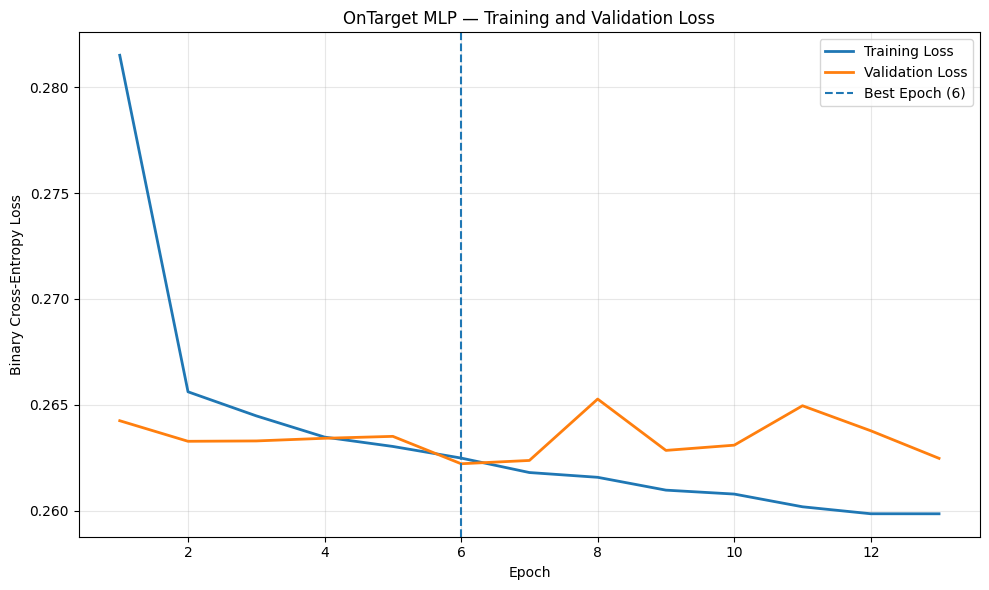

In [ ]:

# ============================================================
# 7.4 Plot MLP Training and Validation Loss
# ============================================================

# Create a list of completed epoch numbers.
epochs = range(1, len(train_losses) + 1)

# Create a figure for the learning curves.
plt.figure(figsize=(10, 6))

# Plot the average training loss after each epoch.
plt.plot(
    epochs,
    train_losses,
    label="Training Loss",
    linewidth=2
)

# Plot the average validation loss after each epoch.
plt.plot(
    epochs,
    val_losses,
    label="Validation Loss",
    linewidth=2
)

# Mark the epoch with the best validation loss.
plt.axvline(
    x=best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

# Add a title and labels.
plt.title("OnTarget MLP — Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

# Display a legend and grid.
plt.legend()
plt.grid(True, alpha=0.3)

# Adjust spacing so labels are visible.
plt.tight_layout()

# Display the completed graph.
plt.show()



## 7.5 Verify the Best Trained Model

After training, we restore the neural network weights from the epoch with the lowest validation loss.

We then perform a final development check to confirm that:

1. The model produces one prediction for each validation shot.
2. All predicted probabilities are between 0 and 1.
3. No invalid numerical values are produced.
4. The restored model achieves the recorded best validation loss.

We use the sigmoid function to convert output logits into predicted goal probabilities.

The held-out testing dataset remains untouched so that the final evaluation can be completed independently.


In [ ]:

# ============================================================
# 7.5 Verify the Best Trained MLP
# ============================================================

# Put the model in evaluation mode.
mlp_model.eval()

# Store validation probabilities.
mlp_val_probs_list = []

# Disable gradient calculations.
with torch.no_grad():

    # Process the validation dataset one batch at a time.
    for features, labels in val_loader:

        # Move the features to the selected device.
        features = features.to(device)

        # Get the raw output logits.
        logits = mlp_model(features)

        # Convert logits into goal probabilities.
        probabilities = torch.sigmoid(logits)

        # Move predictions back to CPU for storage.
        probabilities = probabilities.cpu().numpy()

        # Add the batch predictions to our list.
        mlp_val_probs_list.append(probabilities)

# Combine all batches into one NumPy array.
mlp_val_probs = np.concatenate(
    mlp_val_probs_list
).reshape(-1)

# Recalculate validation loss using the restored model.
restored_val_loss = validate_one_epoch(
    mlp_model,
    val_loader,
    criterion
)

# Confirm that the number of predictions is correct.
assert len(mlp_val_probs) == len(y_val)

# Confirm that all predictions contain valid numbers.
assert np.isfinite(mlp_val_probs).all()

# Confirm all probabilities are between 0 and 1.
assert np.all(
    (mlp_val_probs >= 0) &
    (mlp_val_probs <= 1)
)

# Check that the restored loss matches the best saved loss.
assert np.isclose(
    restored_val_loss,
    best_val_loss,
    atol=1e-5
), "Restored model loss does not match the best loss."

# Display verification results.
print("BEST TRAINED MLP VERIFICATION")
print("-" * 55)

print("Best epoch:", best_epoch)
print(f"Recorded best validation loss: {best_val_loss:.4f}")
print(f"Restored model validation loss: {restored_val_loss:.4f}")

print("\nValidation predictions generated:", len(mlp_val_probs))

print("\nFirst five predicted goal probabilities:")
for i, probability in enumerate(mlp_val_probs[:5], start=1):
    print(f"Shot {i}: {probability * 100:.2f}%")

print("\nAll trained-model verification checks passed!")


BEST TRAINED MLP VERIFICATION
-------------------------------------------------------
Best epoch: 6
Recorded best validation loss: 0.2622
Restored model validation loss: 0.2622

Validation predictions generated: 15850

First five predicted goal probabilities:
Shot 1: 90.25%
Shot 2: 5.04%
Shot 3: 3.81%
Shot 4: 10.37%
Shot 5: 2.18%

All trained-model verification checks passed!


# 8. Model Evaluation

## 8.1 Compare Models on the Validation Set

We compare all models on the validation set using the same three metrics:

1. **Log Loss:** Measures how good the predicted probabilities are. Confident wrong predictions are penalized heavily.
2. **Brier Score:** The mean squared error between the predicted probability and the actual outcome (0 or 1). Lower is better.
3. **ROC-AUC:** Measures how well the model ranks goals above non-goals. A score of 0.5 means random ranking.

We do not use accuracy because only about 10% of shots are goals. A model that predicts "no goal" for every shot would be 90% accurate while learning nothing.

We include two reference points alongside our models:

* **Constant (base rate):** Predicts the training-set goal rate for every shot. Any useful model must beat this.
* **StatsBomb xG:** StatsBomb's professional expected-goals model. It is used only as a benchmark and is never a model input.

All comparisons use the validation set. The testing set remains untouched until the final model is selected.

In [ ]:
# ============================================================
# 8.1 Compare Models on the Validation Set
# ============================================================

# StatsBomb's own xG for the same validation shots (reference only, never a feature).
# X_val kept the original row labels from df, so .loc pulls the matching rows.
statsbomb_val_probs = df.loc[X_val.index, "statsbomb_xg"].to_numpy()

# Trivial baseline: predict the training goal rate for every shot.
base_rate = y_train.mean()
constant_val_probs = np.full(len(y_val), base_rate)

# Run every model through the same metric function from section 5.4.
models = {
    "Constant (base rate)": constant_val_probs,
    "Logistic Regression": logistic_val_probs,
    "MLP": mlp_val_probs,
    "StatsBomb xG (reference)": statsbomb_val_probs,
}

comparison = pd.DataFrame({
    name: calculate_baseline_metrics(y_val, probs)
    for name, probs in models.items()
}).T

print(f"Validation shots: {len(y_val):,} | Goal rate: {y_val.mean():.2%}")
display(comparison.round(4))

Validation shots: 15,850 | Goal rate: 10.15%


,Log Loss,Brier Score,ROC-AUC
Constant (base rate),0.3284,0.0912,0.5000
Logistic Regression,0.2650,0.0760,0.8085
MLP,0.2622,0.0754,0.8120
StatsBomb xG (reference),0.2638,0.0749,0.8089


## 8.2 Calibration of Predicted Probabilities

ROC-AUC only measures whether goals are ranked above non-goals. It does not check whether the predicted probabilities are correct.

A model is **well calibrated** if its probabilities match reality: among all shots given a 20% chance of scoring, about 20% should actually be goals.

To check this, we:

1. Sort validation shots into 10 bins by predicted probability, with an equal number of shots in each bin.
2. Compare the average predicted probability in each bin with the actual goal rate in that bin.
3. Plot the result. A perfectly calibrated model lies on the diagonal line.

Points **below** the diagonal mean the model is overconfident (it predicts more goals than actually happen). Points **above** the diagonal mean it is underconfident.

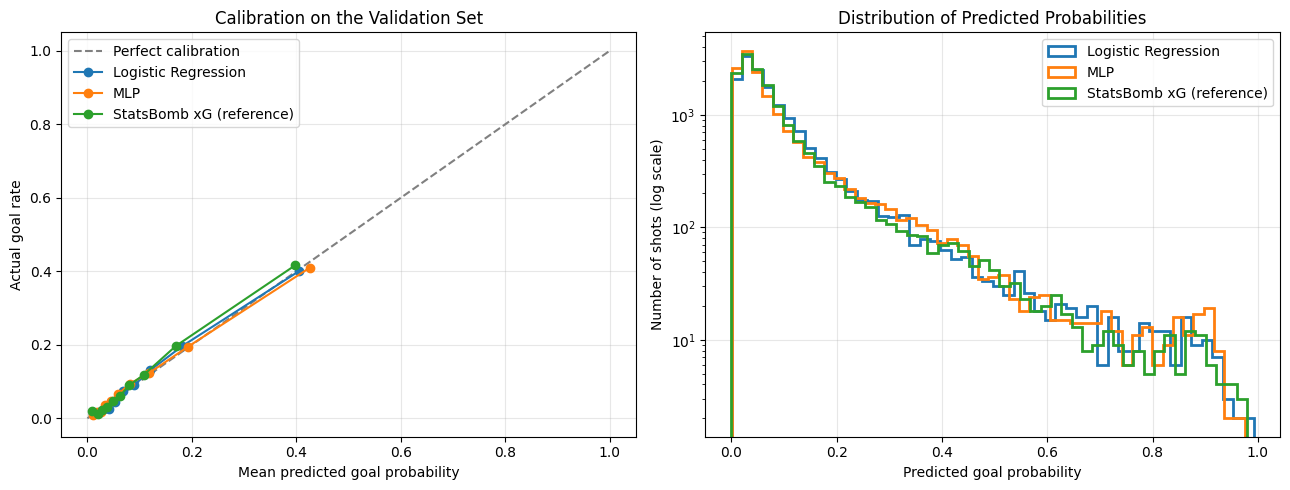

Saved figure to results/calibration_val.png


In [ ]:
# ============================================================
# 8.2 Calibration of Predicted Probabilities
# ============================================================

from sklearn.calibration import calibration_curve
import os

# Folder for saved figures, so the report can reference them.
os.makedirs("results", exist_ok=True)

# Compare the three real models (the constant model is a single point, so it is skipped).
calibration_models = {
    "Logistic Regression": logistic_val_probs,
    "MLP": mlp_val_probs,
    "StatsBomb xG (reference)": statsbomb_val_probs,
}

fig, (ax_cal, ax_hist) = plt.subplots(
    1, 2, figsize=(13, 5)
)

# Left plot: calibration curves.
ax_cal.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")

for name, probs in calibration_models.items():
    actual_rate, mean_predicted = calibration_curve(
        y_val,
        probs,
        n_bins=10,
        strategy="quantile"  # equal number of shots per bin
    )
    ax_cal.plot(mean_predicted, actual_rate, "o-", label=name)

ax_cal.set_xlabel("Mean predicted goal probability")
ax_cal.set_ylabel("Actual goal rate")
ax_cal.set_title("Calibration on the Validation Set")
ax_cal.legend()
ax_cal.grid(True, alpha=0.3)

# Right plot: how predictions are distributed.
for name, probs in calibration_models.items():
    ax_hist.hist(probs, bins=50, histtype="step", linewidth=2, label=name)

ax_hist.set_yscale("log")
ax_hist.set_xlabel("Predicted goal probability")
ax_hist.set_ylabel("Number of shots (log scale)")
ax_hist.set_title("Distribution of Predicted Probabilities")
ax_hist.legend()
ax_hist.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("results/calibration_val.png", dpi=150)
plt.show()

print("Saved figure to results/calibration_val.png")

## 8.3 Save Validation Results

We save the validation metrics and the settings that produced them to `results/val_metrics.json`. Every number reported in our checkpoint and final report can be traced back to this file and to the notebook run that created it.

In [ ]:
# ============================================================
# 8.3 Save Validation Results
# ============================================================

import json
from datetime import datetime

results_record = {
    "created": datetime.now().isoformat(timespec="seconds"),
    "split": "validation",
    "seed": SEED,
    "n_train": len(y_train),
    "n_val": len(y_val),
    "val_goal_rate": float(y_val.mean()),
    "n_features": len(feature_columns),
    "features": feature_columns,
    "mlp_settings": {
        "hidden_layers": [64, 32],
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "best_epoch": best_epoch,
    },
    "metrics": {
        name: {metric: float(value) for metric, value in row.items()}
        for name, row in comparison.iterrows()
    },
}

with open("results/val_metrics.json", "w") as f:
    json.dump(results_record, f, indent=2)

print("Saved results to results/val_metrics.json")

Saved results to results/val_metrics.json


# 9. Seed Robustness

## 9.1 Reusable MLP Training Function

The MLP results in Section 8 come from a single random seed. Because the gap between the MLP and logistic regression is small, we need to check whether it is caused by the architecture or by a lucky initialization.

We wrap the training loop from Section 7 into one function that takes a seed and the training and validation data. The seed controls the initial weights and the order of the mini-batches. The function returns the validation predictions of the best epoch.

Taking the data as arguments lets us reuse the same function for the feature ablation in Section 10.

In [ ]:
# ============================================================
# 9.1 Reusable MLP Training Function
# ============================================================

def set_seed(seed):
    """Seed every source of randomness used in training."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def to_tensors(X_df, y_series):
    """Convert a feature table and labels into PyTorch tensors."""
    X_t = torch.tensor(X_df.to_numpy(), dtype=torch.float32)
    y_t = torch.tensor(y_series.to_numpy(), dtype=torch.float32).reshape(-1, 1)
    return X_t, y_t


def train_mlp_with_seed(seed, X_tr, y_tr, X_va, y_va):
    """Train a fresh MLP with early stopping. Returns (val probabilities, best epoch)."""
    set_seed(seed)

    # Fresh model and optimizer: nothing carries over between runs.
    model = OnTargetMLP(X_tr.shape[1]).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    # A seeded generator fixes the batch order for this run.
    generator = torch.Generator().manual_seed(seed)

    X_tr_t, y_tr_t = to_tensors(X_tr, y_tr)
    X_va_t, y_va_t = to_tensors(X_va, y_va)

    train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t),
                              batch_size=BATCH_SIZE, shuffle=True, generator=generator)
    val_loader = DataLoader(TensorDataset(X_va_t, y_va_t),
                            batch_size=BATCH_SIZE, shuffle=False)

    # Same early stopping rule as Section 7.
    best_loss, best_epoch, best_state, waited = float("inf"), 0, None, 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss = validate_one_epoch(model, val_loader, criterion)

        if val_loss < best_loss - MIN_DELTA:
            best_loss, best_epoch, waited = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            waited += 1
        if waited >= PATIENCE:
            break

    # Restore the best epoch and predict on validation.
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        probs = torch.sigmoid(model(X_va_t.to(device))).cpu().numpy().ravel()

    return probs, best_epoch


# Quick test with one seed before running the full loop.
test_probs, test_epoch = train_mlp_with_seed(0, X_train_scaled, y_train, X_val_scaled, y_val)
print(f"Seed 0 -> best epoch {test_epoch}")
print(calculate_baseline_metrics(y_val, test_probs))

Seed 0 -> best epoch 8
{'Log Loss': 0.2620389185857736, 'Brier Score': np.float64(0.07531614814037615), 'ROC-AUC': np.float64(0.8118537591960537)}


## 9.2 Train Both Models With Multiple Seeds

We train the MLP five times with different seeds on the same training and validation split, and report the mean and standard deviation of each metric.

Logistic regression is also trained with each seed for comparison. Because the lbfgs solver is deterministic and the data split is fixed, we expect logistic regression to give identical results every time (standard deviation of 0). The MLP varies because its initial weights and mini-batch order depend on the seed.

If the MLP's advantage over logistic regression is smaller than the MLP's own variation across seeds, we cannot claim that the MLP is better.

In [ ]:
# ============================================================
# 9.2 Train Both Models With Multiple Seeds
# ============================================================

SEEDS = [0, 1, 2, 3, 4]
seed_rows = []

for seed in SEEDS:
    # Logistic regression with this seed.
    lr = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=seed)
    lr.fit(X_train_scaled, y_train)
    lr_probs = lr.predict_proba(X_val_scaled)[:, 1]
    seed_rows.append({"model": "Logistic Regression", "seed": seed, "best_epoch": None,
                      **calculate_baseline_metrics(y_val, lr_probs)})

    # MLP with this seed.
    start = time.perf_counter()
    mlp_probs, epoch = train_mlp_with_seed(seed, X_train_scaled, y_train, X_val_scaled, y_val)
    seconds = time.perf_counter() - start
    seed_rows.append({"model": "MLP", "seed": seed, "best_epoch": epoch,
                      **calculate_baseline_metrics(y_val, mlp_probs)})

    print(f"Seed {seed} done | MLP best epoch {epoch} | {seconds:.0f}s")

seed_results = pd.DataFrame(seed_rows)

# Mean and standard deviation per model.
metric_cols = ["Log Loss", "Brier Score", "ROC-AUC"]
seed_summary = seed_results.groupby("model")[metric_cols].agg(["mean", "std"])

print("\nPer-seed results:")
display(seed_results.round(4))
print("\nMean ± std across seeds:")
display(seed_summary.round(4))

# Save for the report.
seed_results.to_json("results/seed_robustness.json", orient="records", indent=2)
print("Saved to results/seed_robustness.json")

Seed 0 done | MLP best epoch 8 | 42s
Seed 1 done | MLP best epoch 11 | 50s
Seed 2 done | MLP best epoch 8 | 42s
Seed 3 done | MLP best epoch 6 | 36s
Seed 4 done | MLP best epoch 10 | 46s

Per-seed results:


,model,seed,best_epoch,Log Loss,Brier Score,ROC-AUC
0,Logistic Regression,0,NaN,0.2650,0.0760,0.8085
1,MLP,0,8.0,0.2620,0.0753,0.8119
2,Logistic Regression,1,NaN,0.2650,0.0760,0.8085
3,MLP,1,11.0,0.2620,0.0752,0.8114
4,Logistic Regression,2,NaN,0.2650,0.0760,0.8085
5,MLP,2,8.0,0.2618,0.0753,0.8127
6,Logistic Regression,3,NaN,0.2650,0.0760,0.8085
7,MLP,3,6.0,0.2620,0.0752,0.8111
8,Logistic Regression,4,NaN,0.2650,0.0760,0.8085
9,MLP,4,10.0,0.2622,0.0754,0.8110



Mean ± std across seeds:


Log Loss         Brier Score         ROC-AUC        
                        mean     std        mean     std    mean     std
model                                                                   
Logistic Regression    0.265  0.0000      0.0760  0.0000  0.8085  0.0000
MLP                    0.262  0.0002      0.0753  0.0001  0.8116  0.0007

Saved to results/seed_robustness.json


# 10. Controlled Experiment: Defender Feature Ablation

## 10.1 Train Without Defender Features

Our controlled experiment tests whether information about defenders improves goal predictions. We retrain both models with features removed and keep everything else identical: the same data split, the same five seeds, the same architecture and the same training settings. The full-feature results from Section 9 serve as the control.

We test two variants:

* **A. Without `defenders_in_cone`:** the experiment from our proposal, removing a single feature.
* **B. Without all freeze-frame features:** removing `defenders_in_cone`, `gk_in_cone`, `closest_defender_dist` and `gk_distance_to_goal`.

Variant B is needed because the freeze-frame features are related. If only one is removed, the remaining ones may carry the same information, which would make the defender information look less important than it is.

Because each seed is used in both the full and the ablated runs, we compare them seed by seed (a paired comparison).

In [ ]:
# ============================================================
# 10.1 Train Without Defender Features
# ============================================================

ABLATIONS = {
    "A: no defenders_in_cone": ["defenders_in_cone"],
    "B: no freeze-frame features": [
        "defenders_in_cone",
        "gk_in_cone",
        "closest_defender_dist",
        "gk_distance_to_goal",
    ],
}

ablation_rows = []

for variant, drop_cols in ABLATIONS.items():
    # Drop the columns from already-scaled data. Each column was scaled on its own,
    # so removing some does not change the others.
    X_tr = X_train_scaled.drop(columns=drop_cols)
    X_va = X_val_scaled.drop(columns=drop_cols)
    print(f"\n{variant}: {X_tr.shape[1]} features")

    for seed in SEEDS:
        lr = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=seed)
        lr.fit(X_tr, y_train)
        lr_probs = lr.predict_proba(X_va)[:, 1]
        ablation_rows.append({"variant": variant, "model": "Logistic Regression", "seed": seed,
                              **calculate_baseline_metrics(y_val, lr_probs)})

        mlp_probs, epoch = train_mlp_with_seed(seed, X_tr, y_train, X_va, y_val)
        ablation_rows.append({"variant": variant, "model": "MLP", "seed": seed,
                              **calculate_baseline_metrics(y_val, mlp_probs)})
        print(f"  seed {seed} done | MLP best epoch {epoch}")

# Section 9 results are the full-feature control.
control = seed_results.drop(columns="best_epoch").assign(variant="Full (all features)")
ablation_results = pd.concat([control, pd.DataFrame(ablation_rows)], ignore_index=True)

summary = ablation_results.groupby(["variant", "model"])[metric_cols].agg(["mean", "std"])
print("\nMean ± std across seeds:")
display(summary.round(4))


A: no defenders_in_cone: 36 features
  seed 0 done | MLP best epoch 8
  seed 1 done | MLP best epoch 11
  seed 2 done | MLP best epoch 9
  seed 3 done | MLP best epoch 8
  seed 4 done | MLP best epoch 7

B: no freeze-frame features: 33 features
  seed 0 done | MLP best epoch 8
  seed 1 done | MLP best epoch 9
  seed 2 done | MLP best epoch 9
  seed 3 done | MLP best epoch 8
  seed 4 done | MLP best epoch 7

Mean ± std across seeds:


Log Loss         Brier Score  \
                                                    mean     std        mean   
variant                     model                                              
A: no defenders_in_cone     Logistic Regression   0.2674  0.0000      0.0766   
                            MLP                   0.2643  0.0004      0.0760   
B: no freeze-frame features Logistic Regression   0.2737  0.0000      0.0783   
                            MLP                   0.2705  0.0002      0.0777   
Full (all features)         Logistic Regression   0.2650  0.0000      0.0760   
                            MLP                   0.2620  0.0002      0.0753   

                                                        ROC-AUC          
                                                    std    mean     std  
variant                     model                                        
A: no defenders_in_cone     Logistic Regression  0.0000  0.8036  0.0000  
                            MLP                  0.0001  0.8075  0.0004  
B: no freeze-frame features Logistic Regression  0.0000  0.7912  0.0000  
                            MLP                  0.0000  0.7949  0.0002  
Full (all features)         Logistic Regression  0.0000  0.8085  0.0000  
                            MLP                  0.0001  0.8116  0.0007

In [ ]:
# ============================================================
# 10.2 Paired Difference From the Full Model
# ============================================================

# Line up each ablated run with the full run that used the same model and seed.
full = ablation_results[ablation_results["variant"] == "Full (all features)"]
ablated = ablation_results[ablation_results["variant"] != "Full (all features)"]

paired = ablated.merge(full, on=["model", "seed"], suffixes=("", "_full"))
for m in metric_cols:
    paired[f"Δ {m}"] = paired[m] - paired[f"{m}_full"]

delta_cols = [f"Δ {m}" for m in metric_cols]
delta_summary = paired.groupby(["variant", "model"])[delta_cols].agg(["mean", "std"])

print("Change vs full model (positive Log Loss / Brier = worse, negative AUC = worse):")
display(delta_summary.round(4))

ablation_results.to_json("results/ablation.json", orient="records", indent=2)
print("Saved to results/ablation.json")

Change vs full model (positive Log Loss / Brier = worse, negative AUC = worse):


Δ Log Loss          \
                                                      mean     std   
variant                     model                                    
A: no defenders_in_cone     Logistic Regression     0.0023  0.0000   
                            MLP                     0.0023  0.0003   
B: no freeze-frame features Logistic Regression     0.0086  0.0000   
                            MLP                     0.0085  0.0002   

                                                Δ Brier Score          \
                                                         mean     std   
variant                     model                                       
A: no defenders_in_cone     Logistic Regression        0.0006  0.0000   
                            MLP                        0.0007  0.0001   
B: no freeze-frame features Logistic Regression        0.0022  0.0000   
                            MLP                        0.0024  0.0001   

                                                Δ ROC-AUC          
                                                     mean     std  
variant                     model                                  
A: no defenders_in_cone     Logistic Regression   -0.0049  0.0000  
                            MLP                   -0.0041  0.0004  
B: no freeze-frame features Logistic Regression   -0.0173  0.0000  
                            MLP                   -0.0167  0.0006

Saved to results/ablation.json


# 11. Error Analysis

## 11.1 Most Surprising Shots

Overall metrics can hide systematic mistakes. We look at the validation shots where the MLP was most wrong:

* **Surprising goals:** shots the model gave a very low chance of scoring, but which went in.
* **Missed chances:** shots the model gave a very high chance of scoring, but which did not go in.

For each shot we also show StatsBomb's xG. If StatsBomb's model is equally surprised, the shot was likely unpredictable from pre-shot information (for example, a long-range strike into the top corner). If only our model is surprised, it points to information our features are missing.

In [ ]:
# ============================================================
# 11.1 Most Surprising Shots
# ============================================================

# Validation shots with their original columns. mlp_val_probs is in the same
# order as X_val, because val_loader used shuffle=False.
val_df = df.loc[X_val.index].copy()
val_df["mlp_prob"] = mlp_val_probs
val_df["lr_prob"] = logistic_val_probs

# Turn one-hot columns back into readable labels.
def undo_one_hot(data, prefix):
    cols = [c for c in data.columns if c.startswith(prefix)]
    return data[cols].idxmax(axis=1).str.replace(prefix, "", regex=False)

val_df["body_part"] = undo_one_hot(val_df, "body_part_")
val_df["shot_type"] = undo_one_hot(val_df, "shot_type_")

show_cols = [
    "player_name", "team_name", "distance_to_goal", "shot_angle_deg",
    "body_part", "shot_type", "defenders_in_cone", "one_on_one", "open_goal",
    "outcome_raw", "mlp_prob", "statsbomb_xg",
]

surprising_goals = val_df[val_df["is_goal"] == 1].nsmallest(10, "mlp_prob")
missed_chances = val_df[val_df["is_goal"] == 0].nlargest(10, "mlp_prob")

print("GOALS THE MODEL THOUGHT WERE UNLIKELY")
display(surprising_goals[show_cols].round(3))

print("\nCHANCES THE MODEL WAS CONFIDENT ABOUT, BUT WERE MISSED")
display(missed_chances[show_cols].round(3))

GOALS THE MODEL THOUGHT WERE UNLIKELY


,player_name,team_name,distance_to_goal,shot_angle_deg,body_part,shot_type,defenders_in_cone,one_on_one,open_goal,outcome_raw,mlp_prob,statsbomb_xg
30317,Álvaro Vázquez García,Kerala Blasters,69.048,6.541,Right Foot,Open Play,0,0,0,Goal,0.003,0.004
81547,Raiderlin Nazareth Carrasco Vargas,CD Sporting de Huelva,79.760,5.545,Left Foot,Open Play,0,0,0,Goal,0.004,0.016
83429,Dominique Johanna Anna Petrone Janssen,VfL Wolfsburg WFC,40.082,5.402,Left Foot,Open Play,0,0,0,Goal,0.005,0.007
97095,Samuel Eto''o Fils,Barcelona,38.381,11.694,Right Foot,Open Play,0,0,0,Goal,0.006,0.007
6260,Giulia Gwinn,Germany Women's,19.662,22.723,Right Foot,Open Play,5,0,0,Goal,0.006,0.053
4473,Lucy Hope,Everton LFC,34.455,12.218,Right Foot,Open Play,0,0,0,Goal,0.009,0.008
5057,Sophie Louise Ingle,Chelsea FCW,23.938,16.103,Left Foot,Open Play,2,0,0,Goal,0.009,0.020
78700,Nerea Nevado Gómez,Athletic Club Bilbao,21.949,7.920,Left Foot,Open Play,1,0,0,Goal,0.009,0.006
80491,Fridolina Rolfö,Barcelona WFC,38.205,5.130,Left Foot,Open Play,0,0,0,Goal,0.012,0.008
51826,Lorenzo Insigne,Napoli,34.723,10.477,Right Foot,Open Play,0,0,0,Goal,0.013,0.007



CHANCES THE MODEL WAS CONFIDENT ABOUT, BUT WERE MISSED


,player_name,team_name,distance_to_goal,shot_angle_deg,body_part,shot_type,defenders_in_cone,one_on_one,open_goal,outcome_raw,mlp_prob,statsbomb_xg
104315,Filip Kostić,Serbia,2.828,116.565,Right Foot,Open Play,0,0,1,Wayward,0.950,0.895
74968,Lucas Rodrigues Moura da Silva,Paris Saint-Germain,4.805,79.322,Right Foot,Open Play,0,1,1,Saved,0.911,0.857
29845,Jorge Rolando Pereyra Díaz,Kerala Blasters,4.011,89.839,Left Foot,Open Play,0,0,1,Off T,0.900,0.890
69625,Jean Michaël Seri,OGC Nice,8.050,49.728,Right Foot,Open Play,0,0,1,Off T,0.883,0.865
1992,Vivianne Miedema,Arsenal WFC,2.236,143.973,Right Foot,Open Play,0,1,0,Saved,0.863,0.707
3409,Lauren Hemp,Manchester City WFC,2.236,124.508,Left Foot,Open Play,0,0,1,Saved,0.844,0.668
20657,Olivier Giroud,Arsenal,4.494,82.875,Left Foot,Open Play,0,0,1,Wayward,0.841,0.758
66961,Karim Bellarabi,Bayer Leverkusen,14.227,24.257,Right Foot,Open Play,0,0,1,Wayward,0.836,0.776
23646,Pernille Mosegaard Harder,Chelsea FCW,3.523,97.306,Head,Open Play,0,1,1,Post,0.821,0.321
60842,Pierre-Emerick Aubameyang,Borussia Dortmund,4.717,79.932,Left Foot,Open Play,0,0,1,Off T,0.814,0.794


## 11.2 Performance by Shot Type

We split the validation set into groups (body part, shot type, open goal, one-on-one, pressure and distance) and compare, for each group:

* **Actual goal rate** against the **mean predicted probability**. A large difference means the model is biased for that kind of shot.
* **ROC-AUC within the group:** how well the model ranks shots of the same kind.

Within-group AUC is usually lower than the overall AUC, because part of the overall ranking comes from separating easy groups (close shots) from hard ones (long shots). Groups with few shots give unreliable estimates, so the number of shots is shown alongside.

In [ ]:
# ============================================================
# 11.2 Performance by Shot Type
# ============================================================

val_df["distance_band"] = pd.cut(
    val_df["distance_to_goal"],
    bins=[0, 6, 12, 18, 25, 120],
    labels=["0-6", "6-12", "12-18", "18-25", "25+"],
)

def group_report(data, group_col):
    rows = []
    for group, sub in data.groupby(group_col, observed=True):
        actual = sub["is_goal"].mean()
        predicted = sub["mlp_prob"].mean()
        rows.append({
            group_col: group,
            "shots": len(sub),
            "actual_goal_rate": actual,
            "mean_mlp_prob": predicted,
            "calibration_gap": predicted - actual,   # + overestimates, - underestimates
            "mean_statsbomb_xg": sub["statsbomb_xg"].mean(),
            # AUC needs both goals and non-goals in the group.
            "mlp_auc": roc_auc_score(sub["is_goal"], sub["mlp_prob"])
                       if sub["is_goal"].nunique() == 2 else np.nan,
        })
    return pd.DataFrame(rows)

group_tables = {}
for col in ["body_part", "shot_type", "open_goal", "one_on_one", "under_pressure", "distance_band"]:
    table = group_report(val_df, col)
    group_tables[col] = table
    print(f"\n=== {col} ===")
    display(table.round(3))

# Save every table for the report.
with open("results/error_analysis_groups.json", "w") as f:
    json.dump({k: v.astype({k: str}).to_dict(orient="records") for k, v in group_tables.items()},
              f, indent=2, default=float)
print("\nSaved to results/error_analysis_groups.json")


=== body_part ===


,body_part,shots,actual_goal_rate,mean_mlp_prob,calibration_gap,mean_statsbomb_xg,mlp_auc
0,Head,2563,0.112,0.108,-0.005,0.114,0.775
1,Left Foot,4954,0.100,0.101,0.001,0.094,0.812
2,Other,53,0.264,0.320,0.055,0.274,0.844
3,Right Foot,8280,0.098,0.098,-0.000,0.090,0.822



=== shot_type ===


,shot_type,shots,actual_goal_rate,mean_mlp_prob,calibration_gap,mean_statsbomb_xg,mlp_auc
0,Corner,7,0.571,0.500,-0.072,0.000,0.000
1,Free Kick,699,0.064,0.075,0.010,0.041,0.586
2,Open Play,15144,0.103,0.102,-0.001,0.099,0.817



=== open_goal ===


,open_goal,shots,actual_goal_rate,mean_mlp_prob,calibration_gap,mean_statsbomb_xg,mlp_auc
0,0,15676,0.095,0.094,-0.001,0.090,0.799
1,1,174,0.730,0.755,0.025,0.657,0.780


... (3 outputs left out)

,under_pressure,shots,actual_goal_rate,mean_mlp_prob,calibration_gap,mean_statsbomb_xg,mlp_auc
0,0,11911,0.104,0.106,0.002,0.098,0.818
1,1,3939,0.093,0.085,-0.008,0.091,0.790



=== distance_band ===


,distance_band,shots,actual_goal_rate,mean_mlp_prob,calibration_gap,mean_statsbomb_xg,mlp_auc
0,0-6,501,0.417,0.444,0.026,0.402,0.756
1,6-12,3409,0.178,0.177,-0.001,0.168,0.745
2,12-18,3747,0.124,0.117,-0.007,0.115,0.749
3,18-25,4068,0.057,0.056,-0.001,0.055,0.709
4,25+,4125,0.024,0.027,0.004,0.022,0.719



Saved to results/error_analysis_groups.json



# 12. Final Test Evaluation

## 12.1 Select the Final Models

After completing the validation experiments, we select the final models for testing.

We use the logistic regression baseline from Section 5 and the MLP trained in Section 7.

The MLP contains the restored weights from its best validation checkpoint, which was epoch 6.

We create a separate copy of the trained MLP to preserve these weights.

The five-seed and ablation experiments were used to study model stability and feature importance. They do not replace our selected final model.

We now keep the model settings fixed before using the testing dataset.

The testing dataset will only be used for the final performance evaluation, not for training or choosing new hyperparameters.


In [ ]:

# ============================================================
# 12.1 Select and Freeze the Final Models
# ============================================================

import copy

# Make sure the selected MLP checkpoint is available.
assert best_model_state is not None, (
    "The best trained MLP checkpoint is missing."
)

# Create a separate copy of the final MLP.
# This uses the same 37 -> 64 -> 32 -> 1 architecture.
final_mlp = OnTargetMLP(
    input_size=len(feature_columns)
).to(device)

# Load the best saved weights from Section 7.
# This keeps the final model independent from later runs.
final_mlp.load_state_dict(
    copy.deepcopy(best_model_state)
)

# Put the final MLP into evaluation mode.
final_mlp.eval()

# Store the already-trained logistic regression baseline.
final_logistic = copy.deepcopy(logistic_model)

# Verify that the MLP input size is correct.
assert final_mlp.fc1.in_features == len(feature_columns)

# Verify that the restored MLP has the expected loss.
final_val_loss = validate_one_epoch(
    final_mlp,
    val_loader,
    criterion
)

assert np.isclose(
    final_val_loss,
    best_val_loss,
    atol=1e-5
), "The selected checkpoint does not match the saved model."

print("Final models selected successfully!")

print("\nMLP best epoch:", best_epoch)
print(f"MLP validation loss: {final_val_loss:.4f}")
print("Number of input features:", len(feature_columns))

print("\nFinal models are ready for testing.")


Final models selected successfully!

MLP best epoch: 6
MLP validation loss: 0.2622
Number of input features: 37

Final models are ready for testing.



## 12.2 Evaluate Models on the Testing Dataset

We evaluate the selected models using the testing dataset.

The testing dataset contains 16,270 shots from matches that were not used during training or validation.

We compare four methods:

1. **Constant Baseline:** Predicts the training-set goal rate for every shot.
2. **Logistic Regression:** Our original machine learning baseline.
3. **PyTorch MLP:** Our trained deep learning model.
4. **StatsBomb xG:** An external reference for comparison.

We calculate Log Loss, Brier Score, and ROC-AUC.

Log Loss and Brier Score measure the quality of predicted goal probabilities. Lower values are better.

ROC-AUC measures how well the model ranks goals above non-goals. Higher values are better.

The testing results will be used for the final report and presentation.

No model parameters will be updated during this evaluation.


In [ ]:

# ============================================================
# 12.2 Final Test Evaluation
# ============================================================

# Convert test features into a PyTorch tensor.
# The features were already standardized in Section 4.
X_test_tensor = torch.tensor(
    X_test_scaled.to_numpy(dtype=np.float32),
    dtype=torch.float32
)

# Create a DataLoader for testing.
# We do not need to shuffle testing samples.
test_feature_loader = DataLoader(
    X_test_tensor,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ------------------------------------------------------------
# Generate MLP predictions
# ------------------------------------------------------------

# Store the predicted probabilities from each batch.
mlp_test_batches = []

# Keep the model in evaluation mode.
final_mlp.eval()

# Do not calculate gradients or update model weights.
with torch.no_grad():

    # Process each batch of testing shots.
    for features in test_feature_loader:

        # Move features to the correct device.
        features = features.to(device)

        # Generate raw output logits.
        logits = final_mlp(features)

        # Convert logits into goal probabilities.
        probabilities = torch.sigmoid(logits)

        # Move predictions back to the CPU.
        mlp_test_batches.append(
            probabilities.cpu().numpy().reshape(-1)
        )

# Combine all predicted probabilities.
mlp_test_probs = np.concatenate(mlp_test_batches)

# ------------------------------------------------------------
# Generate logistic regression predictions
# ------------------------------------------------------------

logistic_test_probs = final_logistic.predict_proba(
    X_test_scaled
)[:, 1]

# ------------------------------------------------------------
# Prepare comparison baselines
# ------------------------------------------------------------

# Constant model predicts the training goal rate.
constant_test_probs = np.full(
    len(y_test),
    y_train.mean()
)

# StatsBomb's xG is used only as a reference.
# It was never included in our model input features.
statsbomb_test_probs = df.loc[
    X_test.index,
    "statsbomb_xg"
].to_numpy(dtype=float)

# ------------------------------------------------------------
# Verify predictions before calculating metrics
# ------------------------------------------------------------

test_predictions = {
    "Constant Baseline": constant_test_probs,
    "Logistic Regression": logistic_test_probs,
    "OnTarget MLP": mlp_test_probs,
    "StatsBomb xG (Reference)": statsbomb_test_probs
}

for name, probabilities in test_predictions.items():

    # Confirm that every test shot has one prediction.
    assert len(probabilities) == len(y_test), (
        f"Incorrect prediction count for {name}"
    )

    # Check that all predictions are valid numbers.
    assert np.isfinite(probabilities).all(), (
        f"Invalid predictions found for {name}"
    )

    # Probabilities must be between zero and one.
    assert np.all(
        (probabilities >= 0) &
        (probabilities <= 1)
    ), f"Invalid probability range for {name}"

# ------------------------------------------------------------
# Calculate final performance metrics
# ------------------------------------------------------------

# Reuse the metric function from Section 5.
test_results = pd.DataFrame({
    name: calculate_baseline_metrics(
        y_test,
        probabilities
    )
    for name, probabilities in test_predictions.items()
}).T

# Display the final results.
print("FINAL ONTARGET TEST RESULTS")
print("=" * 60)

print("Testing shots:", len(y_test))
print(f"Actual goal rate: {y_test.mean() * 100:.2f}%")

display(test_results.round(4))

# Calculate the difference between MLP and logistic regression.
# Negative Log Loss and Brier differences are improvements.
mlp_vs_logistic = (
    test_results.loc["OnTarget MLP"]
    - test_results.loc["Logistic Regression"]
)

print("\nMLP - Logistic Regression")
print(mlp_vs_logistic.round(4))

print("\nFinal test evaluation completed.")
print("No model weights were updated.")


FINAL ONTARGET TEST RESULTS
Testing shots: 16270
Actual goal rate: 10.41%


,Log Loss,Brier Score,ROC-AUC
Constant Baseline,0.3339,0.0932,0.5000
Logistic Regression,0.2678,0.0764,0.8038
OnTarget MLP,0.2654,0.0757,0.8081
StatsBomb xG (Reference),0.2650,0.0750,0.8086



MLP - Logistic Regression
Log Loss      -0.0025
Brier Score   -0.0007
ROC-AUC        0.0043
dtype: float64

Final test evaluation completed.
No model weights were updated.



## 12.3 Visualize Final Test Results

We create bar charts to compare the models using their final test results.

The charts show Log Loss, Brier Score, and ROC-AUC.

These visualizations help us understand whether the MLP improves on logistic regression and how it compares with the StatsBomb xG reference.

We save the charts for the final project report and presentation.


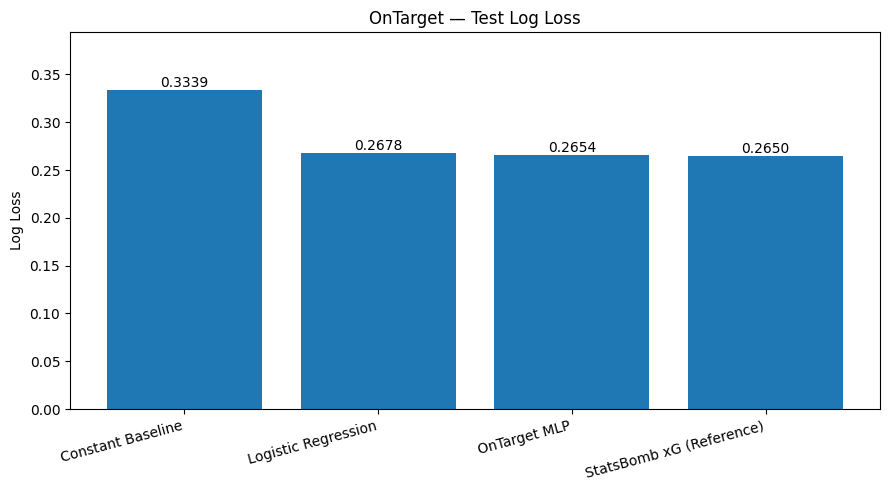

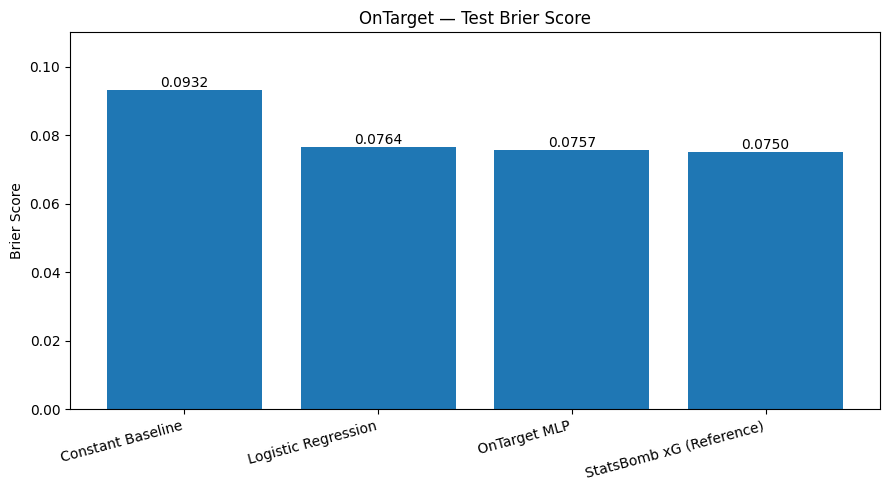

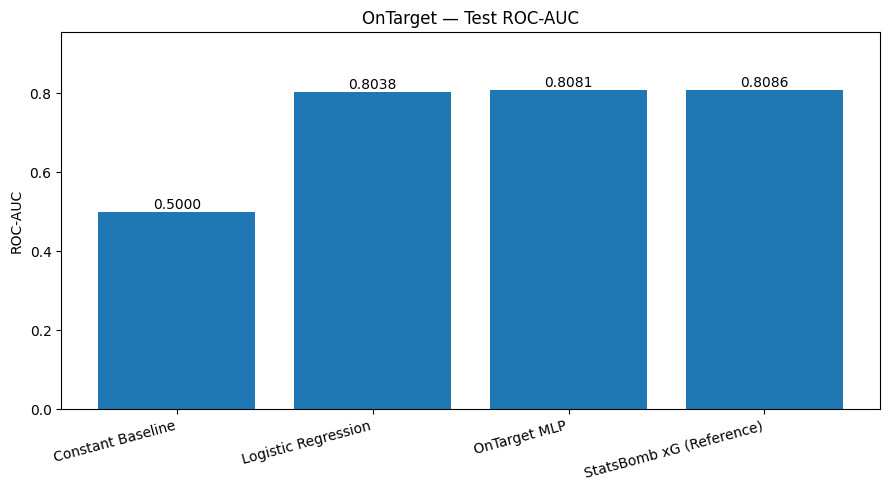

Final test comparison graphs saved!


In [ ]:

# ============================================================
# 12.3 Plot Final Test Results
# ============================================================

from pathlib import Path

# Create the results folder if it does not exist.
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

# Create separate plots for each evaluation metric.
metrics = ["Log Loss", "Brier Score", "ROC-AUC"]

for metric in metrics:

    # Create a new figure.
    plt.figure(figsize=(9, 5))

    # Draw the model comparison.
    bars = plt.bar(
        test_results.index,
        test_results[metric]
    )

    # Display each numerical result above its bar.
    for bar in bars:

        value = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f"{value:.4f}",
            ha="center",
            va="bottom"
        )

    # Add the chart title and labels.
    plt.title(f"OnTarget — Test {metric}")
    plt.ylabel(metric)

    # Rotate model names for readability.
    plt.xticks(rotation=15, ha="right")

    # Keep enough room for the labels.
    plt.ylim(0, test_results[metric].max() * 1.18)
    plt.tight_layout()

    # Save the figure.
    file_name = (
        metric.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    plt.savefig(
        RESULTS_DIR / f"test_{file_name}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

print("Final test comparison graphs saved!")



# 13. Save the Trained Models

## 13.1 Save Model Weights and Settings

We save the trained models so they can be used again without repeating the training process.

The PyTorch MLP contains the weights and biases from the best validation checkpoint.

We also save the logistic regression baseline, StandardScaler, and selected feature information.

These files allow us to load the models and generate predictions in future Colab sessions.

The original dataset is not included in the saved files.


In [ ]:

# ============================================================
# 13.1 Save the Trained Models
# ============================================================

# Import libraries for saving files.
import torch
import joblib
import json
from pathlib import Path

# Create a folder for our trained model files.
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Save the trained PyTorch MLP
# ------------------------------------------------------------

# Save the best MLP weights from the training process.
# These are the selected weights from epoch 6.
torch.save(
    best_model_state,
    MODEL_DIR / "ontarget_mlp.pth"
)

# ------------------------------------------------------------
# Save the logistic regression baseline
# ------------------------------------------------------------

# Save the trained logistic regression model.
joblib.dump(
    logistic_model,
    MODEL_DIR / "logistic_regression.joblib"
)

# ------------------------------------------------------------
# Save the StandardScaler
# ------------------------------------------------------------

# Save the scaler fitted using training data only.
joblib.dump(
    scaler,
    MODEL_DIR / "standard_scaler.joblib"
)

# ------------------------------------------------------------
# Save the feature configuration
# ------------------------------------------------------------

# Store the exact input feature order and architecture.
model_config = {
    "feature_columns": list(feature_columns),
    "numerical_features": list(numerical_features),
    "binary_features": list(binary_features),
    "input_size": len(feature_columns),
    "hidden_layers": [64, 32],
    "output_size": 1,
    "best_epoch": int(best_epoch),
    "random_seed": int(SEED)
}

# Save the configuration as a JSON file.
with open(
    MODEL_DIR / "model_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(model_config, file, indent=4)

# ------------------------------------------------------------
# Verify that all files were created
# ------------------------------------------------------------

print("TRAINED MODELS SAVED")
print("-" * 45)

for file in sorted(MODEL_DIR.iterdir()):
    print(f"{file.name} ({file.stat().st_size:,} bytes)")

print("\nAll model files saved successfully!")


TRAINED MODELS SAVED
---------------------------------------------
logistic_regression.joblib (2,175 bytes)
model_config.json (2,415 bytes)
ontarget_mlp.pth (21,329 bytes)
standard_scaler.joblib (1,135 bytes)

All model files saved successfully!


In [ ]:

# ============================================================
# 13.2 Verify and Download Saved Models
# ============================================================

import shutil
from google.colab import files

# Create a new model with the same architecture.
loaded_mlp = OnTargetMLP(
    input_size=len(feature_columns)
).to(device)

# Load the saved weights into the new model.
saved_weights = torch.load(
    MODEL_DIR / "ontarget_mlp.pth",
    map_location=device,
    weights_only=True
)

loaded_mlp.load_state_dict(saved_weights)
loaded_mlp.eval()

# Use ten validation shots to compare predictions.
sample = torch.tensor(
    X_val_scaled.iloc[:10].to_numpy(dtype="float32"),
    dtype=torch.float32
).to(device)

# Do not update any model weights.
final_mlp.eval()

with torch.no_grad():

    # Predictions from the original final model.
    original_output = final_mlp(sample)

    # Predictions from the reloaded model.
    loaded_output = loaded_mlp(sample)

# Both models should produce the same predictions.
assert torch.allclose(
    original_output,
    loaded_output,
    atol=1e-6
), "Saved model predictions do not match."

print("Saved MLP verified successfully!")

# Verify the other saved files.
loaded_logistic = joblib.load(
    MODEL_DIR / "logistic_regression.joblib"
)

loaded_scaler = joblib.load(
    MODEL_DIR / "standard_scaler.joblib"
)

with open(
    MODEL_DIR / "model_config.json",
    encoding="utf-8"
) as file:
    loaded_config = json.load(file)

assert loaded_config["feature_columns"] == feature_columns
assert loaded_logistic.n_features_in_ == len(feature_columns)
assert loaded_scaler.n_features_in_ == len(numerical_features)

print("All saved model checks passed!")

# Compress the model folder into one ZIP archive.
zip_path = shutil.make_archive(
    "OnTarget_models",
    "zip",
    root_dir=".",
    base_dir="models"
)

# Download the archive to your computer.
files.download(zip_path)

print("\nModels verified and downloaded successfully!")


Saved MLP verified successfully!
All saved model checks passed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Models verified and downloaded successfully!



# 14. Soccer Shot Analysis and Visualization

## 14.1 Prepare Shot Data for Visualization

In this section, we analyze the results of the trained OnTarget MLP using real soccer shots.

We use the held-out testing dataset, which contains 16,270 shots from matches not used during training.

Each shot contains its location, distance, shooting angle, defensive information, and actual goal outcome.

We combine this information with the goal probabilities predicted by our MLP.

This allows us to visualize where higher-probability shots were taken and compare model predictions with real outcomes.

The analysis uses the existing trained model. No new training is performed.


In [ ]:

# ============================================================
# 14.1 Prepare Test Data for Soccer Visualization
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Rectangle, Arc

# Create a folder for our soccer visualization results.
VIS_DIR = Path("results/soccer_visualizations")
VIS_DIR.mkdir(parents=True, exist_ok=True)

# Get the original shot information for the test set.
# X_test keeps its original row indexes from the dataset.
shot_analysis = df.loc[X_test.index].copy()

# Add the MLP probabilities calculated in Section 12.
# The predictions are in the same order as X_test_scaled.
shot_analysis["predicted_xg"] = mlp_test_probs

# Add the actual goal outcomes for comparison.
shot_analysis["actual_goal"] = y_test.to_numpy()

# Check that each shot has exactly one prediction.
assert len(shot_analysis) == len(mlp_test_probs)

# Confirm that row indexes have not changed order.
assert shot_analysis.index.equals(X_test.index)

# Check that shot coordinates and probabilities are valid.
required_columns = [
    "x",
    "y",
    "distance_to_goal",
    "shot_angle_rad",
    "defenders_in_cone",
    "predicted_xg",
    "actual_goal"
]

assert shot_analysis[required_columns].notna().all().all(), (
    "Some required values are missing."
)

# Confirm that probabilities are between 0 and 1.
assert shot_analysis["predicted_xg"].between(0, 1).all()

# Display basic dataset information.
print("SOCCER SHOT ANALYSIS")
print("-" * 50)

print("Total test shots:", len(shot_analysis))
print("Actual goals:", int(shot_analysis["actual_goal"].sum()))

print(
    "Average predicted goal probability:",
    f"{shot_analysis['predicted_xg'].mean() * 100:.2f}%"
)

print(
    "Actual goal conversion rate:",
    f"{shot_analysis['actual_goal'].mean() * 100:.2f}%"
)

print("\nShot coordinate ranges:")
print("X:", shot_analysis["x"].min(),
      "to", shot_analysis["x"].max())
print("Y:", shot_analysis["y"].min(),
      "to", shot_analysis["y"].max())

# Show the first five shots.
display(
    shot_analysis[
        ["x", "y", "distance_to_goal",
         "defenders_in_cone", "predicted_xg",
         "actual_goal"]
    ].head()
)

print("\nVisualization data prepared successfully!")


SOCCER SHOT ANALYSIS
--------------------------------------------------
Total test shots: 16270
Actual goals: 1693
Average predicted goal probability: 10.11%
Actual goal conversion rate: 10.41%

Shot coordinate ranges:
X: 30.8 to 120.0
Y: 0.3 to 78.5


,x,y,distance_to_goal,defenders_in_cone,predicted_xg,actual_goal
46,113.8,35.6,7.6026,0,0.165668,0
47,115.4,36.6,5.7201,0,0.487162,1
48,110.2,50.8,14.5836,0,0.100176,1
49,110.4,23.9,18.7449,0,0.056914,0
50,89.8,48.6,31.4006,0,0.028109,0



Visualization data prepared successfully!



## 14.2 Shot Location Map

We plot the shooting positions on a soccer pitch using StatsBomb coordinates.

Each circle represents a real shot from the testing dataset.

The color and size of the circle show the probability of scoring predicted by OnTarget.

Larger and darker circles represent shots with higher predicted scoring probabilities.

We display the attacking half of the pitch because most goal-scoring opportunities occur closer to the opponent's goal.

This visualization helps us see where high-probability shots were taken.

The displayed shots are a reproducible sample from the test dataset to reduce visual overlap.


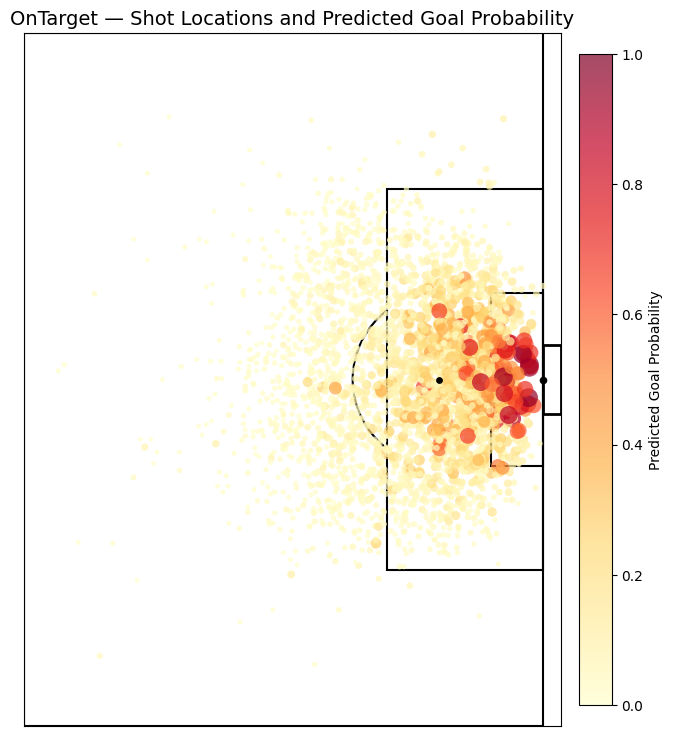

Shots displayed: 3000
Total attacking-half shots: 16254

Shot location map saved successfully!


In [ ]:

# ============================================================
# 14.2 Plot Shot Locations and Goal Probabilities
# ============================================================

# ------------------------------------------------------------
# Create a reusable soccer pitch drawing function
# ------------------------------------------------------------

def draw_soccer_pitch(ax):

    # Set the attacking half of the StatsBomb pitch.
    # The opponent's goal is on the right at x = 120.
    ax.set_xlim(60, 122)
    ax.set_ylim(80, 0)

    # Draw the outer boundaries of the attacking half.
    ax.add_patch(
        Rectangle(
            (60, 0),
            60,
            80,
            fill=False,
            edgecolor="black",
            linewidth=1.5
        )
    )

    # Draw the penalty area.
    # StatsBomb penalty area starts at x = 102.
    ax.add_patch(
        Rectangle(
            (102, 18),
            18,
            44,
            fill=False,
            edgecolor="black",
            linewidth=1.5
        )
    )

    # Draw the six-yard box.
    ax.add_patch(
        Rectangle(
            (114, 30),
            6,
            20,
            fill=False,
            edgecolor="black",
            linewidth=1.5
        )
    )

    # Draw the goal behind the goal line.
    ax.add_patch(
        Rectangle(
            (120, 36),
            2,
            8,
            fill=False,
            edgecolor="black",
            linewidth=2
        )
    )

    # Draw the penalty spot.
    ax.scatter(
        108,
        40,
        color="black",
        s=15,
        zorder=5
    )

    # Draw the penalty arc.
    ax.add_patch(
        Arc(
            (108, 40),
            width=20,
            height=20,
            theta1=127,
            theta2=233,
            color="black",
            linewidth=1.5
        )
    )

    # Draw the centre of the goal.
    ax.scatter(
        120,
        40,
        color="black",
        s=20,
        zorder=5
    )

    # Keep the pitch proportions correct.
    ax.set_aspect("equal")

    # Hide the axis marks.
    ax.set_xticks([])
    ax.set_yticks([])


# ------------------------------------------------------------
# Select shots from the attacking half
# ------------------------------------------------------------

attacking_shots = shot_analysis[
    shot_analysis["x"].between(60, 120)
    & shot_analysis["y"].between(0, 80)
].copy()

# Use at most 3,000 shots to reduce overlapping circles.
# The fixed seed makes the sample reproducible.
shot_sample = attacking_shots.sample(
    n=min(3000, len(attacking_shots)),
    random_state=SEED
)

# ------------------------------------------------------------
# Draw the shot map
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 9))

draw_soccer_pitch(ax)

# Plot the actual shooting positions.
# Circle size and color represent predicted xG.
scatter = ax.scatter(
    shot_sample["x"],
    shot_sample["y"],

    # Higher xG produces larger circles.
    s=12 + shot_sample["predicted_xg"] * 180,

    # Higher xG is represented by stronger colors.
    c=shot_sample["predicted_xg"],

    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    alpha=0.7,
    edgecolors="none"
)

# Add a color bar explaining the probabilities.
colorbar = plt.colorbar(
    scatter,
    ax=ax,
    fraction=0.035,
    pad=0.02
)

colorbar.set_label("Predicted Goal Probability")

# Add a title.
ax.set_title(
    "OnTarget — Shot Locations and Predicted Goal Probability",
    fontsize=14
)

# Save the completed figure.
plt.savefig(
    VIS_DIR / "shot_location_map.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Shots displayed:", len(shot_sample))
print("Total attacking-half shots:", len(attacking_shots))
print("\nShot location map saved successfully!")



## 14.3 Shooting-Zone Probability Heatmap

We divide the attacking half of the soccer pitch into smaller shooting zones.

For each zone, we calculate:

- The number of shots taken.
- The average predicted goal probability.
- The actual number of goals scored.
- The observed goal conversion rate.

We use all available test shots rather than a visual sample.

Zones containing fewer than 30 shots are hidden because their averages may be unreliable.

The heatmap shows the average predicted scoring chance of shots taken from each area.

These results depend on the shooting circumstances recorded in the dataset, including defensive pressure and goalkeeper positioning.


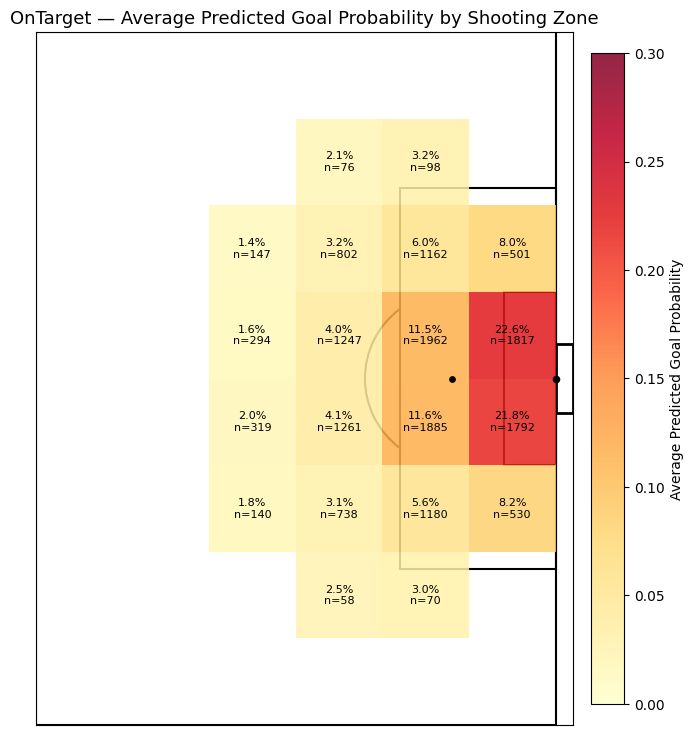

Shooting-zone heatmap saved successfully!
Minimum shots per displayed zone: 30
Valid zones: 20


In [ ]:

# ============================================================
# 14.3 Create Shooting-Zone Probability Heatmap
# ============================================================

# Use 10-by-10 coordinate zones across the attacking half.
x_edges = np.arange(60, 121, 10)
y_edges = np.arange(0, 81, 10)

# Count the number of shots in each zone.
shot_counts, _, _ = np.histogram2d(
    attacking_shots["x"],
    attacking_shots["y"],
    bins=[x_edges, y_edges]
)

# Calculate the sum of predicted probabilities in each zone.
# This represents the expected number of goals.
predicted_goals, _, _ = np.histogram2d(
    attacking_shots["x"],
    attacking_shots["y"],
    bins=[x_edges, y_edges],
    weights=attacking_shots["predicted_xg"]
)

# Calculate the number of actual goals in each zone.
actual_goals, _, _ = np.histogram2d(
    attacking_shots["x"],
    attacking_shots["y"],
    bins=[x_edges, y_edges],
    weights=attacking_shots["actual_goal"]
)

# Calculate zone averages safely.
# Empty zones are initially set to NaN.
average_xg = np.full(
    shot_counts.shape,
    np.nan,
    dtype=float
)

actual_goal_rate = np.full(
    shot_counts.shape,
    np.nan,
    dtype=float
)

# Only show zones with at least 30 shots.
minimum_shots = 30
valid_zones = shot_counts >= minimum_shots

# Calculate average predicted probability per zone.
average_xg[valid_zones] = (
    predicted_goals[valid_zones]
    / shot_counts[valid_zones]
)

# Calculate observed goal conversion rate per zone.
actual_goal_rate[valid_zones] = (
    actual_goals[valid_zones]
    / shot_counts[valid_zones]
)

# ------------------------------------------------------------
# Plot the average predicted goal probability
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 9))

# Draw the soccer pitch.
draw_soccer_pitch(ax)

# Plot the average predicted scoring probability.
# The highest displayed zone is around 23%.
# Using a 0-30% scale makes differences easier to see.
heatmap = ax.pcolormesh(
    x_edges,
    y_edges,
    np.ma.masked_invalid(average_xg.T),
    cmap="YlOrRd",
    vmin=0,
    vmax=0.30,
    shading="flat",
    alpha=0.85
)


# Add the sample count to every visible zone.
for i in range(len(x_edges) - 1):
    for j in range(len(y_edges) - 1):

        if valid_zones[i, j]:

            # Calculate the centre of the zone.
            center_x = (x_edges[i] + x_edges[i + 1]) / 2
            center_y = (y_edges[j] + y_edges[j + 1]) / 2

            # Show the average xG and number of shots.
            ax.text(
                center_x,
                center_y,
                f"{average_xg[i, j] * 100:.1f}%\n"
                f"n={int(shot_counts[i, j])}",
                ha="center",
                va="center",
                fontsize=8,
                color="black"
            )

# Explain the color scale.
colorbar = plt.colorbar(
    heatmap,
    ax=ax,
    fraction=0.035,
    pad=0.02
)

colorbar.set_label("Average Predicted Goal Probability")

ax.set_title(
    "OnTarget — Average Predicted Goal Probability by Shooting Zone",
    fontsize=13
)

plt.savefig(
    VIS_DIR / "shooting_zone_heatmap.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Shooting-zone heatmap saved successfully!")
print("Minimum shots per displayed zone:", minimum_shots)
print("Valid zones:", valid_zones.sum())



## 14.4 Compare Predicted and Actual Goals by Zone

We compare the MLP's predicted probabilities with the actual goal outcomes in each shooting zone.

For each zone, we calculate the average predicted goal probability and the actual goal conversion rate.

This helps us determine whether areas with higher predicted probabilities also have higher observed scoring rates.

We also calculate the total expected goals by adding the predicted probabilities.

We only rank zones with at least 50 shots to reduce the influence of very small samples.

The results help us identify high-probability shooting areas in our test dataset.


In [ ]:

# ============================================================
# 14.4 Compare Predicted and Actual Goals by Shooting Zone
# ============================================================

# Create a list to store results for each pitch zone.
zone_rows = []

# Go through every shooting zone.
for i in range(len(x_edges) - 1):
    for j in range(len(y_edges) - 1):

        # Count the shots taken from this zone.
        count = int(shot_counts[i, j])

        # Ignore empty zones.
        if count == 0:
            continue

        # Calculate average predicted probability.
        avg_probability = predicted_goals[i, j] / count

        # Calculate the actual goal conversion rate.
        observed_rate = actual_goals[i, j] / count

        # Store the results.
        zone_rows.append({

            "Zone": (
                f"x={x_edges[i]}-{x_edges[i + 1]}, "
                f"y={y_edges[j]}-{y_edges[j + 1]}"
            ),

            "Shots": count,

            "Predicted Goal Rate (%)": avg_probability * 100,

            "Actual Goal Rate (%)": observed_rate * 100,

            "Expected Goals": predicted_goals[i, j],

            "Actual Goals": int(actual_goals[i, j])
        })

# Convert the results into a DataFrame.
zone_results = pd.DataFrame(zone_rows)

# Only rank zones containing at least 50 shots.
ranked_zones = zone_results[
    zone_results["Shots"] >= 50
].copy()

# Sort from highest to lowest predicted goal probability.
ranked_zones = ranked_zones.sort_values(
    "Predicted Goal Rate (%)",
    ascending=False
)

print("TOP SHOOTING ZONES BY PREDICTED GOAL PROBABILITY")
print("-" * 65)

# Display the ten highest-probability zones.
display(ranked_zones.head(10).round(2))

# Save the full zone summary.
zone_results.to_csv(
    VIS_DIR / "shooting_zone_analysis.csv",
    index=False
)

# Find the highest-probability zone with enough samples.
if len(ranked_zones) > 0:

    top_zone = ranked_zones.iloc[0]

    print("\nHighest-ranked shooting zone:")
    print("Zone:", top_zone["Zone"])
    print("Shots:", int(top_zone["Shots"]))

    print(
        "Average predicted goal probability:",
        f"{top_zone['Predicted Goal Rate (%)']:.2f}%"
    )

    print(
        "Actual goal conversion rate:",
        f"{top_zone['Actual Goal Rate (%)']:.2f}%"
    )

print("\nShooting-zone analysis completed!")


TOP SHOOTING ZONES BY PREDICTED GOAL PROBABILITY
-----------------------------------------------------------------


,Zone,Shots,Predicted Goal Rate (%),Actual Goal Rate (%),Expected Goals,Actual Goals
39,"x=110-120, y=30-40",1817,22.61,21.19,410.85,385
40,"x=110-120, y=40-50",1792,21.77,22.38,390.18,401
33,"x=100-110, y=40-50",1885,11.61,13.74,218.80,259
32,"x=100-110, y=30-40",1962,11.52,12.54,225.98,246
41,"x=110-120, y=50-60",530,8.23,10.57,43.64,56
38,"x=110-120, y=20-30",501,7.97,7.58,39.92,38
31,"x=100-110, y=20-30",1162,5.97,5.85,69.32,68
34,"x=100-110, y=50-60",1180,5.64,5.42,66.49,64
25,"x=90-100, y=40-50",1261,4.08,4.68,51.41,59
24,"x=90-100, y=30-40",1247,4.00,3.21,49.92,40



Highest-ranked shooting zone:
Zone: x=110-120, y=30-40
Shots: 1817
Average predicted goal probability: 22.61%
Actual goal conversion rate: 21.19%

Shooting-zone analysis completed!



## 14.5 Shooting Distance and Angle Analysis

We analyze how shooting distance and angle relate to predicted scoring probability.

Shots are grouped into distance and angle ranges.

For each group, we compare the average predicted probability with the actual goal conversion rate.

This allows us to investigate whether shots closer to the goal or with wider shooting angles generally have better scoring chances.

The analysis uses real test shots and does not change the trained model.

We also display the number of shots in each group so the results can be interpreted carefully.


DISTANCE ANALYSIS


,distance_group,shots,predicted_rate,actual_rate
0,0–6,573,46.139999,46.25
1,6–12,3458,17.240000,17.09
2,12–18,3906,11.340000,12.93
3,18–25,4172,5.410000,5.13
4,25–35,3642,2.920000,2.88
5,35+,519,1.680000,2.50


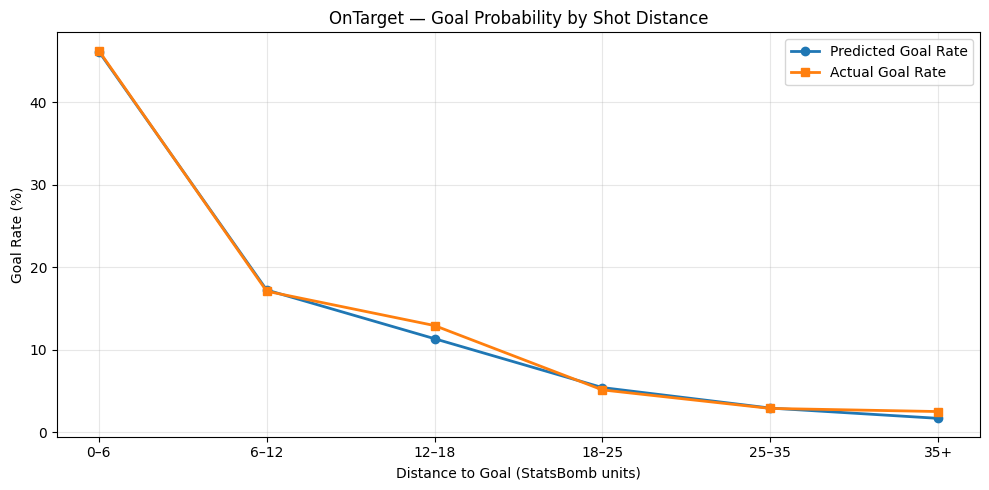


SHOOTING ANGLE ANALYSIS


,angle_group,shots,predicted_rate,actual_rate
0,0–10,408,3.960000,3.92
1,10–20,7766,4.130000,4.04
2,20–30,3760,10.420000,12.42
3,30–40,1852,14.270000,13.88
4,40–60,1742,19.590000,18.83
5,60–90,612,36.509998,35.62
6,90–180,130,66.750000,71.54


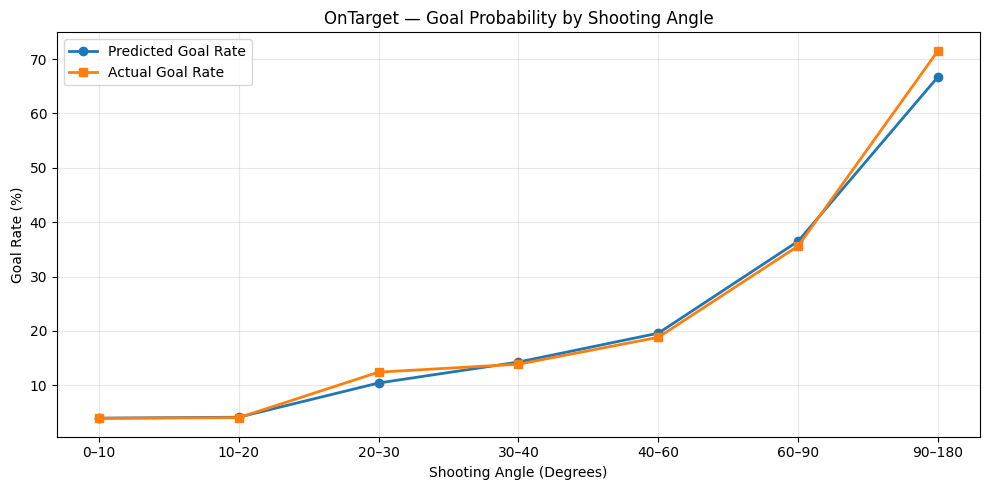


Distance and angle analysis completed!


In [ ]:

# ============================================================
# 14.5 Analyze Shot Distance and Shooting Angle
# ============================================================

# Create a copy so the original analysis data stays unchanged.
analysis = shot_analysis.copy()

# ------------------------------------------------------------
# Group shots by distance to goal
# ------------------------------------------------------------

# Distance uses StatsBomb pitch coordinate units.
distance_bins = [0, 6, 12, 18, 25, 35, np.inf]

distance_labels = [
    "0–6",
    "6–12",
    "12–18",
    "18–25",
    "25–35",
    "35+"
]

# Assign each shot to a distance range.
analysis["distance_group"] = pd.cut(
    analysis["distance_to_goal"],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=True
)

# Calculate predicted and actual scoring rates by distance.
distance_results = (
    analysis.groupby(
        "distance_group",
        observed=True
    )
    .agg(
        shots=("actual_goal", "size"),
        predicted_rate=("predicted_xg", "mean"),
        actual_rate=("actual_goal", "mean")
    )
    .reset_index()
)

# Convert probability values into percentages.
distance_results["predicted_rate"] *= 100
distance_results["actual_rate"] *= 100

print("DISTANCE ANALYSIS")
display(distance_results.round(2))

# ------------------------------------------------------------
# Visualize distance results
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    distance_results["distance_group"].astype(str),
    distance_results["predicted_rate"],
    marker="o",
    linewidth=2,
    label="Predicted Goal Rate"
)

ax.plot(
    distance_results["distance_group"].astype(str),
    distance_results["actual_rate"],
    marker="s",
    linewidth=2,
    label="Actual Goal Rate"
)

ax.set_title("OnTarget — Goal Probability by Shot Distance")
ax.set_xlabel("Distance to Goal (StatsBomb units)")
ax.set_ylabel("Goal Rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    VIS_DIR / "distance_analysis.png",
    dpi=250
)

plt.show()

# ------------------------------------------------------------
# Group shots by shooting angle
# ------------------------------------------------------------

# Convert the angle from radians to degrees for readability.
analysis["angle_degrees"] = np.degrees(
    analysis["shot_angle_rad"]
)

# Group shots using shooting-angle ranges.
angle_bins = [0, 10, 20, 30, 40, 60, 90, 180]

angle_labels = [
    "0–10",
    "10–20",
    "20–30",
    "30–40",
    "40–60",
    "60–90",
    "90–180"
]

analysis["angle_group"] = pd.cut(
    analysis["angle_degrees"],
    bins=angle_bins,
    labels=angle_labels,
    include_lowest=True
)

# Calculate average predicted and actual goal rates.
angle_results = (
    analysis.groupby(
        "angle_group",
        observed=True
    )
    .agg(
        shots=("actual_goal", "size"),
        predicted_rate=("predicted_xg", "mean"),
        actual_rate=("actual_goal", "mean")
    )
    .reset_index()
)

# Convert rates into percentages.
angle_results["predicted_rate"] *= 100
angle_results["actual_rate"] *= 100

print("\nSHOOTING ANGLE ANALYSIS")
display(angle_results.round(2))

# ------------------------------------------------------------
# Visualize shooting angle results
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    angle_results["angle_group"].astype(str),
    angle_results["predicted_rate"],
    marker="o",
    linewidth=2,
    label="Predicted Goal Rate"
)

ax.plot(
    angle_results["angle_group"].astype(str),
    angle_results["actual_rate"],
    marker="s",
    linewidth=2,
    label="Actual Goal Rate"
)

ax.set_title("OnTarget — Goal Probability by Shooting Angle")
ax.set_xlabel("Shooting Angle (Degrees)")
ax.set_ylabel("Goal Rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    VIS_DIR / "angle_analysis.png",
    dpi=250
)

plt.show()

# Save both summary tables.
distance_results.to_csv(
    VIS_DIR / "distance_analysis.csv",
    index=False
)

angle_results.to_csv(
    VIS_DIR / "angle_analysis.csv",
    index=False
)

print("\nDistance and angle analysis completed!")



## 14.6 Defensive Positioning Analysis

We analyze how the number of defenders in the shooting cone relates to goal probability.

Shots are grouped based on the number of defenders between the shooter and the goal.

For each group, we calculate the average predicted scoring probability and the actual goal conversion rate.

This helps us understand how defensive positioning is associated with shot quality.

These results are observational because shots with different defender counts may also differ in distance, angle, and other conditions.

Our earlier controlled feature-removal experiment provides separate evidence about the predictive value of defender information.


DEFENSIVE POSITIONING ANALYSIS


,defender_group,shots,predicted_rate,actual_rate
0,0 defenders,7603,14.52,15.40
1,1 defender,5567,6.75,6.57
2,2 defenders,1971,5.25,5.18
3,3+ defenders,1129,5.42,4.78


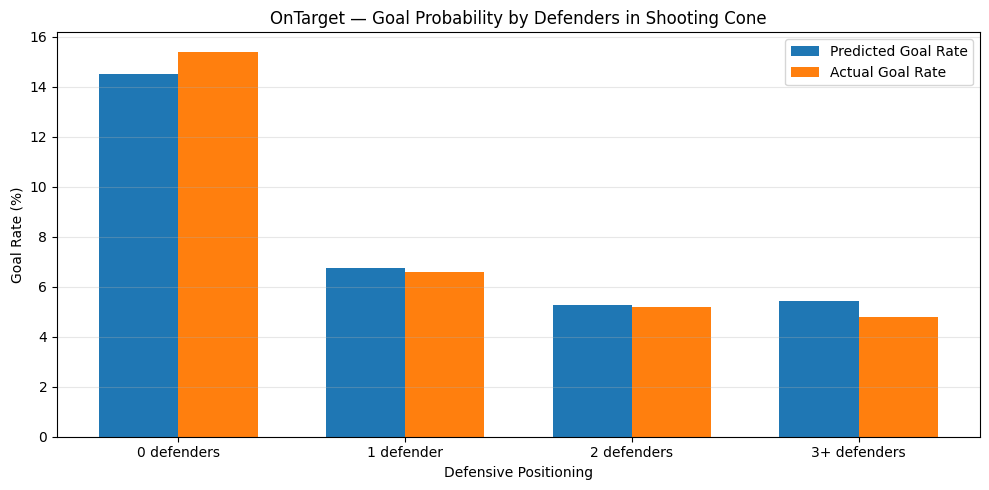


Defensive positioning analysis completed!


In [ ]:

# ============================================================
# 14.6 Defensive Positioning Analysis
# ============================================================

# Create groups based on defenders in the shooting cone.
defender_bins = [-1, 0, 1, 2, np.inf]

defender_labels = [
    "0 defenders",
    "1 defender",
    "2 defenders",
    "3+ defenders"
]

analysis["defender_group"] = pd.cut(
    analysis["defenders_in_cone"],
    bins=defender_bins,
    labels=defender_labels
)

# Calculate predicted and actual rates for each group.
defender_results = (
    analysis.groupby(
        "defender_group",
        observed=True
    )
    .agg(
        shots=("actual_goal", "size"),
        predicted_rate=("predicted_xg", "mean"),
        actual_rate=("actual_goal", "mean")
    )
    .reset_index()
)

# Convert probabilities into percentages.
defender_results["predicted_rate"] *= 100
defender_results["actual_rate"] *= 100

print("DEFENSIVE POSITIONING ANALYSIS")
display(defender_results.round(2))

# ------------------------------------------------------------
# Plot predicted and actual goal rates
# ------------------------------------------------------------

labels = defender_results["defender_group"].astype(str)

positions = np.arange(len(labels))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    positions - bar_width / 2,
    defender_results["predicted_rate"],
    width=bar_width,
    label="Predicted Goal Rate"
)

ax.bar(
    positions + bar_width / 2,
    defender_results["actual_rate"],
    width=bar_width,
    label="Actual Goal Rate"
)

ax.set_xticks(positions)
ax.set_xticklabels(labels)

ax.set_title(
    "OnTarget — Goal Probability by Defenders in Shooting Cone"
)
ax.set_xlabel("Defensive Positioning")
ax.set_ylabel("Goal Rate (%)")

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    VIS_DIR / "defender_analysis.png",
    dpi=250
)

plt.show()

# Save the results.
defender_results.to_csv(
    VIS_DIR / "defender_analysis.csv",
    index=False
)

print("\nDefensive positioning analysis completed!")



## 14.7 Visualization Summary

We completed the soccer shot analysis using predictions from the final OnTarget MLP.

The visualizations show shooting locations, average predicted scoring probabilities, observed goals, shooting distance, shooting angle, and defensive conditions.

These results help us interpret the trained model in a soccer context.

The analysis is based on shots from the held-out testing dataset. It describes observed shooting situations and does not prove that any position is always the best location to shoot.

The graphs and summary tables are saved for the final report and presentation.


In [ ]:

# ============================================================
# 14.7 Final Visualization Summary
# ============================================================

# Display the number of shots used.
print("ONTARGET SOCCER ANALYSIS SUMMARY")
print("=" * 55)

print("Total test shots:", len(shot_analysis))

print(
    "Actual goals:",
    int(shot_analysis["actual_goal"].sum())
)

print(
    "Expected goals:",
    round(shot_analysis["predicted_xg"].sum(), 2)
)

print(
    "Average predicted goal probability:",
    f"{shot_analysis['predicted_xg'].mean() * 100:.2f}%"
)

print(
    "Actual goal conversion rate:",
    f"{shot_analysis['actual_goal'].mean() * 100:.2f}%"
)

# Show all files generated during this section.
print("\nSAVED VISUALIZATION FILES")
print("-" * 55)

for file in sorted(VIS_DIR.iterdir()):
    print("-", file.name)

print("\nSection 14 completed successfully!")


ONTARGET SOCCER ANALYSIS SUMMARY
Total test shots: 16270
Actual goals: 1693
Expected goals: 1644.33
Average predicted goal probability: 10.11%
Actual goal conversion rate: 10.41%

SAVED VISUALIZATION FILES
-------------------------------------------------------
- angle_analysis.csv
- angle_analysis.png
- defender_analysis.csv
- defender_analysis.png
- distance_analysis.csv
- distance_analysis.png
- shooting_zone_analysis.csv
- shooting_zone_heatmap.png
- shot_location_map.png

Section 14 completed successfully!



# 15. Real-World Shot Prediction Demonstration

## 15.1 Load and Verify the Trained Model

In this section, we demonstrate how OnTarget predicts the probability of scoring in real soccer situations.

We use the trained MLP saved in Section 13.

The model uses 37 input features, including shooting position, distance, angle, technique, defensive information, and goalkeeper positioning.

We load the saved weights, StandardScaler, and feature configuration.

This allows us to generate predictions without retraining the model.

We use real shots from the held-out test dataset to verify that the saved model reproduces the original predictions.


In [ ]:

# ============================================================
# 15.1 Load and Verify the Trained OnTarget Model
# ============================================================

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path

# Locate the saved model files from Section 13.
MODEL_DIR = Path("models")

# Load the saved feature configuration.
with open(
    MODEL_DIR / "model_config.json",
    "r",
    encoding="utf-8"
) as file:
    demo_config = json.load(file)

# Get the exact feature names and order.
demo_feature_columns = demo_config["feature_columns"]
demo_numerical_features = demo_config["numerical_features"]

# Load the StandardScaler fitted during training.
demo_scaler = joblib.load(
    MODEL_DIR / "standard_scaler.joblib"
)

# Create the same MLP architecture used during training.
demo_model = OnTargetMLP(
    input_size=demo_config["input_size"]
).to(device)

# Load the saved trained weights.
demo_weights = torch.load(
    MODEL_DIR / "ontarget_mlp.pth",
    map_location=device,
    weights_only=True
)

demo_model.load_state_dict(demo_weights)

# Set the model to evaluation mode.
demo_model.eval()

# Confirm that the feature order matches the notebook.
assert demo_feature_columns == list(feature_columns)

# Confirm that the scaler matches the numerical features.
assert list(demo_scaler.feature_names_in_) == demo_numerical_features

# Create a reusable prediction function.
def predict_goal_probability(shot_features):

    # Keep the exact feature order used during training.
    X_input = shot_features[demo_feature_columns].copy()

    # Apply the saved scaling values.
    # We do not fit the scaler again.
    X_input[demo_numerical_features] = demo_scaler.transform(
        X_input[demo_numerical_features]
    )

    # Convert all input values to float32.
    X_input = X_input.astype(np.float32)

    # Check for missing or invalid values.
    if not np.isfinite(X_input.to_numpy()).all():
        raise ValueError("Invalid shot input values found.")

    # Convert the input into a PyTorch tensor.
    X_tensor = torch.tensor(
        X_input.to_numpy(),
        dtype=torch.float32
    ).to(device)

    # Generate probabilities without updating weights.
    demo_model.eval()

    with torch.no_grad():

        logits = demo_model(X_tensor)

        probabilities = torch.sigmoid(
            logits
        ).cpu().numpy().reshape(-1)

    return probabilities


# Verify that the saved model reproduces the test results.
# Use the original, unscaled test features.
check_predictions = predict_goal_probability(
    X_test.iloc[:20]
)

# Compare against predictions generated in Section 12.
assert np.allclose(
    check_predictions,
    mlp_test_probs[:20],
    atol=1e-6
), "Saved model predictions do not match Section 12."

print("Saved MLP loaded successfully!")
print("Input features:", len(demo_feature_columns))
print("Model predictions verified against Section 12.")
print("No model retraining was performed.")


Saved MLP loaded successfully!
Input features: 37
Model predictions verified against Section 12.
No model retraining was performed.



## 15.2 Interactive Shot Opportunity Estimator

We create an interactive tool that allows users to explore scoring probabilities for different shooting situations.

The user chooses a shooting position using sliders, along with the number of defenders, pressure, and shooting body part.

The tool searches the training dataset for real shots with matching conditions and nearby locations.

The saved OnTarget MLP predicts the goal probability for each comparable shot using all 37 recorded input features.

We calculate the average predicted probability across these shots and display the number of examples used.

This approach accounts for different recorded goalkeeper positions, defender distances, shooting techniques, and other conditions without requiring the user to select every feature.

The estimate represents comparable historical shooting situations near the selected position, rather than an exact simulation at that point.

If there are not enough nearby matching shots, the tool does not generate a prediction.

No retraining is performed.


In [ ]:

# ============================================================
# 15.2 Interactive OnTarget Shot Opportunity Estimator
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output

# ------------------------------------------------------------
# Step 1: Prepare the historical reference data
# ------------------------------------------------------------

# Use only the original, unscaled TRAINING features.
# The held-out test set remains separate.
reference_shots = X_train[
    demo_feature_columns
].copy()

# Check that the positions are in StatsBomb coordinates.
assert reference_shots["x"].between(0, 120).all()
assert reference_shots["y"].between(0, 80).all()

# Check the required features.
required_features = [
    "x",
    "y",
    "distance_to_goal",
    "shot_angle_rad",
    "defenders_in_cone",
    "under_pressure"
]

missing = [
    col for col in required_features
    if col not in demo_feature_columns
]

if missing:
    raise ValueError(
        f"Required features are missing: {missing}"
    )

# Find the body-part features used by the MLP.
body_columns = [
    col for col in demo_feature_columns
    if col.startswith("body_part_")
]

preferred_body_parts = [
    "Right Foot",
    "Left Foot",
    "Head",
    "Other"
]

body_parts = [
    part for part in preferred_body_parts
    if f"body_part_{part}" in body_columns
]

# Include any additional body-part categories.
for col in body_columns:
    part = col.replace("body_part_", "", 1)

    if part not in body_parts:
        body_parts.append(part)

if not body_parts:
    raise ValueError("No body-part features found.")


# ------------------------------------------------------------
# Step 2: Define matching rules
# ------------------------------------------------------------

# Search nearby positions in StatsBomb coordinate units.
# Start with a small radius and expand only when needed.
SEARCH_RADII = [3, 5, 8, 10]

# Require at least this many comparable recorded shots.
MIN_MATCHES = 15

# Limit the number of shots used to keep inference fast.
MAX_MATCHES = 250

GOAL_X = 120.0
GOAL_Y = 40.0


def find_comparable_shots(
    x,
    y,
    defenders,
    pressure,
    body_part
):
    """
    Find real training shots that match:
    - defender count
    - pressure
    - body part

    Then select nearby shooting positions.

    We keep the complete original feature rows.
    No historical feature values are changed.
    """

    body_column = f"body_part_{body_part}"

    # Match the conditions chosen by the user.
    matching_conditions = reference_shots[
        (reference_shots["defenders_in_cone"] == defenders)
        &
        (reference_shots["under_pressure"] == pressure)
        &
        (reference_shots[body_column] == 1)
    ].copy()

    if matching_conditions.empty:
        return None, None, 0

    # Calculate the distance from each historical shot
    # to the selected position.
    matching_conditions["location_difference"] = np.hypot(
        matching_conditions["x"] - x,
        matching_conditions["y"] - y
    )

    # Search within gradually increasing radii.
    for radius in SEARCH_RADII:

        nearby = matching_conditions[
            matching_conditions["location_difference"] <= radius
        ].copy()

        # Only return an estimate when enough shots exist.
        if len(nearby) >= MIN_MATCHES:

            # Use the closest matches if there are too many.
            nearby = nearby.nsmallest(
                MAX_MATCHES,
                "location_difference"
            )

            return nearby, radius, len(matching_conditions)

    # Not enough nearby matching examples.
    return None, None, len(matching_conditions)


# ------------------------------------------------------------
# Step 3: Create the interactive controls
# ------------------------------------------------------------

# Move toward or away from goal.
x_slider = widgets.IntSlider(
    value=105,
    min=60,
    max=119,
    step=1,
    description="Towards Goal:",
    continuous_update=True,
    style={"description_width": "125px"},
    layout=widgets.Layout(width="520px")
)

# Move across the pitch.
y_slider = widgets.IntSlider(
    value=40,
    min=0,
    max=80,
    step=1,
    description="Across Pitch:",
    continuous_update=True,
    style={"description_width": "125px"},
    layout=widgets.Layout(width="520px")
)

# Select how many defenders are in the shooting cone.
defenders_slider = widgets.IntSlider(
    value=1,
    min=0,
    max=4,
    step=1,
    description="Defenders:",
    continuous_update=False,
    style={"description_width": "125px"},
    layout=widgets.Layout(width="520px")
)

# Select whether the shooter is under pressure.
pressure_checkbox = widgets.Checkbox(
    value=False,
    description="Under Pressure",
    indent=False
)

# Select the shooting body part.
body_selector = widgets.Dropdown(
    options=body_parts,
    description="Body Part:",
    style={"description_width": "125px"},
    layout=widgets.Layout(width="350px")
)

# Button for generating the prediction.
predict_button = widgets.Button(
    description="Estimate Goal Probability",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="260px")
)

# Separate output areas.
pitch_output = widgets.Output()
result_output = widgets.Output()


# ------------------------------------------------------------
# Step 4: Live soccer pitch visualization
# ------------------------------------------------------------

def update_live_pitch(change=None):
    """
    Update the shooting-position marker whenever
    the user moves the X or Y slider.
    """

    x = x_slider.value
    y = y_slider.value

    # Distance is used for display only.
    distance = np.hypot(
        GOAL_X - x,
        GOAL_Y - y
    )

    with pitch_output:

        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(7, 5.5))

        # Draw the pitch created in Section 14.
        draw_soccer_pitch(ax)

        # Show the user-selected shooting position.
        ax.scatter(
            x,
            y,
            s=260,
            color="darkorange",
            edgecolor="black",
            linewidth=2,
            zorder=10
        )

        # Draw a line toward the centre of goal.
        ax.plot(
            [x, GOAL_X],
            [y, GOAL_Y],
            linestyle="--",
            color="darkorange",
            linewidth=2,
            zorder=5
        )

        ax.set_title(
            "Selected Shooting Position\n"
            f"Distance to Goal: {distance:.1f} pitch units",
            fontsize=12,
            fontweight="bold"
        )

        plt.tight_layout()
        plt.show()
        plt.close(fig)


# Redraw the pitch as the position changes.
x_slider.observe(
    update_live_pitch,
    names="value"
)

y_slider.observe(
    update_live_pitch,
    names="value"
)


# ------------------------------------------------------------
# Step 5: Generate the average model prediction
# ------------------------------------------------------------

def run_shot_estimation(button):
    """
    Use real comparable training shots to estimate
    the average goal probability.

    Every matched shot keeps all 37 original features.
    The trained MLP predicts each shot separately.
    """

    with result_output:

        clear_output(wait=True)

        # Get the user-selected conditions.
        x = float(x_slider.value)
        y = float(y_slider.value)

        defenders = int(defenders_slider.value)
        pressure = int(pressure_checkbox.value)
        body_part = body_selector.value

        # --------------------------------------------
        # Find comparable historical shots
        # --------------------------------------------

        matches, radius, condition_count = (
            find_comparable_shots(
                x,
                y,
                defenders,
                pressure,
                body_part
            )
        )

        # Do not invent a result when data is limited.
        if matches is None:

            print("ONTARGET — INSUFFICIENT COMPARABLE DATA")
            print("=" * 55)

            print(
                "Not enough nearby training shots match "
                "the selected conditions."
            )

            print(
                f"\nTotal shots matching the conditions: "
                f"{condition_count:,}"
            )

            print(
                "At least 15 matches within 10 pitch units "
                "are required."
            )

            print(
                "\nTry adjusting the shooting position, "
                "defender count, pressure, or body part."
            )

            return

        # --------------------------------------------
        # Run the saved MLP on every matching shot
        # --------------------------------------------

        # Remove the helper column.
        # Use only the 37 model input features.
        model_inputs = matches[
            demo_feature_columns
        ].copy()

        # This function loads the saved scaler and MLP.
        # No training is performed.
        probabilities = predict_goal_probability(
            model_inputs
        )

        # Average the model predictions.
        average_probability = float(
            np.mean(probabilities)
        )

        # Calculate the variation across the matched shots.
        lower_percentile = float(
            np.percentile(probabilities, 10)
        )

        upper_percentile = float(
            np.percentile(probabilities, 90)
        )

        # Calculate useful information about the matches.
        number_of_matches = len(matches)

        average_position_difference = float(
            matches["location_difference"].mean()
        )

        # --------------------------------------------
        # Display the main result
        # --------------------------------------------

        print("ONTARGET — SHOT OPPORTUNITY ESTIMATE")
        print("=" * 55)

        print(
            f"Selected Position: ({x:.0f}, {y:.0f})"
        )

        print(
            f"Distance to Goal: "
            f"{np.hypot(GOAL_X-x, GOAL_Y-y):.2f} pitch units"
        )

        print(f"Defenders in Cone: {defenders}")

        print(
            f"Under Pressure: "
            f"{'Yes' if pressure else 'No'}"
        )

        print(f"Body Part: {body_part}")

        print("\nESTIMATED GOAL PROBABILITY")
        print("=" * 55)

        print(f"{average_probability * 100:.2f}%")

        print(
            f"\nBased on {number_of_matches:,} "
            "comparable historical shots."
        )

        # --------------------------------------------
        # Show the predicted probability visually
        # --------------------------------------------

        fig, ax = plt.subplots(figsize=(9, 2.6))

        ax.barh(
            ["Comparable Shots"],
            [average_probability * 100],
            height=0.4,
            color="darkorange"
        )

        ax.text(
            min(average_probability * 100 + 2, 96),
            0,
            f"{average_probability * 100:.2f}%",
            va="center",
            fontweight="bold",
            fontsize=12
        )

        ax.set_xlim(0, 105)

        ax.set_xlabel(
            "Average Predicted Goal Probability (%)"
        )

        ax.set_title(
            "OnTarget — Estimated Scoring Chance",
            fontweight="bold"
        )

        ax.grid(
            axis="x",
            linestyle="--",
            alpha=0.2
        )

        ax.set_axisbelow(True)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

        # --------------------------------------------
        # Explain the comparable-shot information
        # --------------------------------------------

        print("\nCOMPARABLE SHOT INFORMATION")
        print("-" * 55)

        print(
            f"Matching shots used: "
            f"{number_of_matches:,}"
        )

        print(
            f"Search radius: "
            f"{radius} pitch units"
        )

        print(
            f"Average location difference: "
            f"{average_position_difference:.2f} pitch units"
        )

        print(
            f"Individual prediction 10th–90th percentiles: "
            f"{lower_percentile*100:.2f}% – "
            f"{upper_percentile*100:.2f}%"
        )

        # --------------------------------------------
        # Summarize goalkeeper and defender conditions
        # --------------------------------------------

        print("\nRECORDED MATCH CONDITIONS")
        print("-" * 55)

        # How often was the goalkeeper in the shooting cone?
        if "gk_in_cone" in matches.columns:

            goalkeeper_cone_rate = (
                matches["gk_in_cone"].mean() * 100
            )

            print(
                f"Goalkeeper in shooting cone: "
                f"{goalkeeper_cone_rate:.1f}% of matched shots"
            )

        # Show the recorded goalkeeper-to-goal distance.
        if "gk_distance_to_goal" in matches.columns:

            gk_distances = matches[
                "gk_distance_to_goal"
            ].dropna()

            if len(gk_distances) > 0:

                print(
                    "Median goalkeeper distance to goal: "
                    f"{gk_distances.median():.2f} pitch units"
                )

                print(
                    "Goalkeeper distance range: "
                    f"{gk_distances.min():.2f} – "
                    f"{gk_distances.max():.2f} pitch units"
                )

        # Show the closest recorded defender distance.
        if "closest_defender_dist" in matches.columns:

            defender_distances = matches[
                "closest_defender_dist"
            ].dropna()

            if len(defender_distances) > 0:

                print(
                    "Median closest defender distance: "
                    f"{defender_distances.median():.2f} pitch units"
                )

        # --------------------------------------------
        # Explain what the estimate means
        # --------------------------------------------

        print("\nINTERPRETATION")
        print("-" * 55)

        print(
            "The result is the average MLP prediction "
            "for comparable recorded training shots."
        )

        print(
            "All matched shots use their complete, "
            "original 37 input features."
        )

        print(
            "The selected position defines a nearby "
            "search area, not an exact simulated shot."
        )

        print(
            "The 10th–90th percentile range shows variation "
            "among matched predictions, not a confidence interval."
        )

        print(
            "This is an exploratory estimate, not a "
            "guaranteed scoring probability."
        )


# Connect the prediction button.
predict_button.on_click(run_shot_estimation)


# ------------------------------------------------------------
# Step 6: Clear old results when inputs change
# ------------------------------------------------------------

def clear_previous_result(change=None):
    """
    Remove a previous estimate after the user
    changes any shooting condition.
    """

    with result_output:
        clear_output(wait=True)


for control in [
    x_slider,
    y_slider,
    defenders_slider,
    pressure_checkbox,
    body_selector
]:
    control.observe(
        clear_previous_result,
        names="value"
    )


# ------------------------------------------------------------
# Step 7: Display the interactive interface
# ------------------------------------------------------------

title = widgets.HTML(
    "<h2>OnTarget — Interactive Shot Opportunity Estimator</h2>"
)

position_title = widgets.HTML(
    "<h3>1. Choose Your Shooting Position</h3>"
)

conditions_title = widgets.HTML(
    "<h3>2. Choose Shooting Conditions</h3>"
)

position_section = widgets.VBox([
    position_title,
    x_slider,
    y_slider,
    pitch_output
])

conditions_section = widgets.VBox([
    conditions_title,
    defenders_slider,
    pressure_checkbox,
    body_selector,
    predict_button
])

interface = widgets.VBox([
    title,
    position_section,
    conditions_section,
    result_output
])

display(interface)

# Show the initial position.
update_live_pitch()

print("Interactive shot opportunity estimator ready!")


Interactive shot opportunity estimator ready!
